### TRAVAUX PRATIQUES : MACHINE LEARNING
**Séance 2 : Classification et métriques (jeu de données Adult)**

## Membres du groupe
| Nom | Prénom | INE |
|---|---|---|
| **ZOUNGRANA** | **ROSALIE** |**N00097420062** |
| **KAMAGATE** | **YOUSSOUF** | **N02651020211** |

## Configuration de l'environnement
On importe les bibliothèque.

 ### Imports standard 

In [5]:

import time, warnings
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Imports Scikit-learn 

In [2]:
  
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, matthews_corrcoef)

# Mission D1 : préparer Adult et établir une référence
## D1.1 – Charger les données sans modifier les fichiers originaux
**Question :** Chargez les données sans modifier les fichiers originaux. Inspectez les types, catégories, marqueurs de valeurs manquantes (notamment `?`), distributions et fréquence de la cible.

In [3]:
#  Les noms des colonnes (les fichiers n'ont pas d'en-tête)

colonnes = ["age", "workclass", "fnlwgt", "education", "education-num",
            "marital-status", "occupation", "relationship", "race", "sex",
            "capital-gain", "capital-loss", "hours-per-week",
            "native-country", "income"]


In [6]:
#  Charger adult.data

df_data = pd.read_csv("data/adult.data", names=colonnes, na_values="?", skipinitialspace=True)

In [7]:
#  Charger adult.test

#    - skiprows=1 : on saute la 1re ligne, qui est un commentaire
df_test_brut = pd.read_csv("data/adult.test", names=colonnes, na_values="?", skipinitialspace=True, skiprows=1)


In [8]:
#  Afficher la taille des deux fichiers (lignes, colonnes)
print("adult.data :", df_data.shape)
print("adult.test :", df_test_brut.shape)

#  Afficher les 5 premières lignes
df_data.head()

adult.data : (32561, 15)
adult.test : (16281, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [9]:
# On regroupe les deux fichiers en un seul tableau pour l'inspection
df = pd.concat([df_data, df_test_brut], ignore_index=True)

In [10]:
# Taille et types des colonnes
print("Nombre de lignes et de colonnes :", df.shape)
df.info()

# Valeurs manquantes
manquants = df.isna().sum()                          
pourcentage = (manquants / len(df) * 100).round(2)   

# On CRÉE le tableau
tableau = pd.DataFrame({"nombre": manquants, "%": pourcentage})

#  On garde seulement les colonnes qui ont des valeurs manquantes
tableau = tableau[tableau["nombre"] > 0]

#  On trie du plus grand au plus petit pourcentage
tableau = tableau.sort_values("%", ascending=False)

#  On AFFICHE le tableau final
print("\nValeurs manquantes :")
print(tableau)

Nombre de lignes et de colonnes : (48842, 15)
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB

Valeurs manquantes :
                nombre     %
occupation        2809  5.75

In [11]:
# La cible : combien de personnes dans chaque classe ?
print("\nCible (libellés bruts) :")
print(df["income"].value_counts())               
print(df["income"].value_counts(normalize=True)) 


Cible (libellés bruts) :
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64
income
<=50K     0.506122
<=50K.    0.254596
>50K      0.160538
>50K.     0.078744
Name: proportion, dtype: float64


In [12]:
print("\nLibellés bruts de la cible (avant harmonisation)")
print(df["income"].value_counts())


Libellés bruts de la cible (avant harmonisation)
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


In [13]:
print("\nStatistiques des variables numériques")
display(df.describe().T.round(2))


Statistiques des variables numériques


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0


In [14]:
print("\nModalités des variables catégorielles")
for c in df.select_dtypes(exclude="number").columns.drop("income"):
    print(f"{c:15s}: {df[c].nunique():2d} modalités ; plus fréquente = {df[c].mode()[0]}")


Modalités des variables catégorielles
workclass      :  8 modalités ; plus fréquente = Private
education      : 16 modalités ; plus fréquente = HS-grad
marital-status :  7 modalités ; plus fréquente = Married-civ-spouse
occupation     : 14 modalités ; plus fréquente = Prof-specialty
relationship   :  6 modalités ; plus fréquente = Husband
race           :  5 modalités ; plus fréquente = White
sex            :  2 modalités ; plus fréquente = Male
native-country : 41 modalités ; plus fréquente = United-States


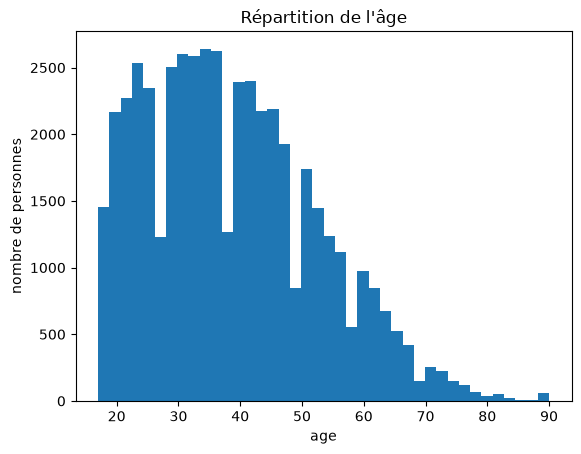

In [15]:
# Histogramme de l'âge
plt.hist(df["age"], bins=40)          
plt.title("Répartition de l'âge")
plt.xlabel("age")
plt.ylabel("nombre de personnes")
plt.show()

Description du graphique : il compte les personnes pour chaque âge. La plupart ont entre 20 et 45 ans, et il y en a de moins en moins après 50 ans. La moitié des personnes a moins de 37 ans.

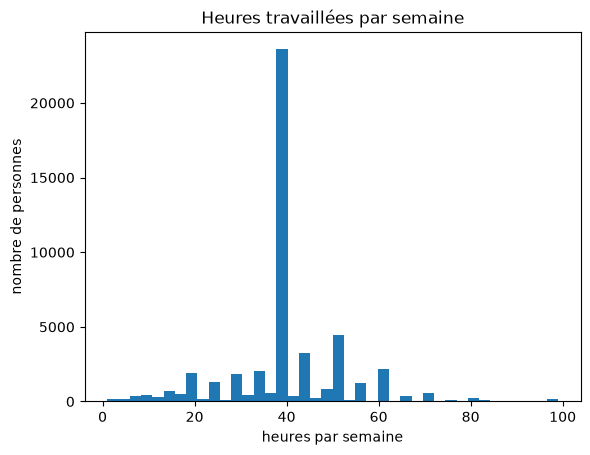

In [16]:
#  Histogramme des heures travaillées par semaine
plt.hist(df["hours-per-week"], bins=40)
plt.title("Heures travaillées par semaine")
plt.xlabel("heures par semaine")
plt.ylabel("nombre de personnes")
plt.show()


Description du graphique : chaque barre compte les personnes pour un nombre d'heures de travail par semaine. La barre à 40 heures est de loin la plus haute, car c'est la durée la plus courante. Très peu de personnes travaillent moins de 20 heures ou plus de 60 heures.

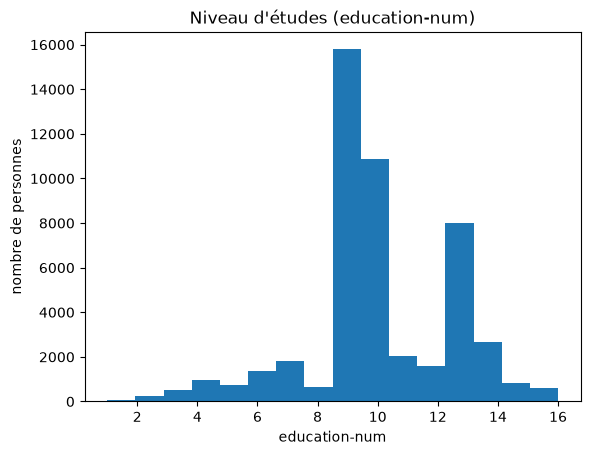

In [17]:
#  Histogramme du niveau d'études (education-num)
plt.hist(df["education-num"], bins=16)
plt.title("Niveau d'études (education-num)")
plt.xlabel("education-num")
plt.ylabel("nombre de personnes")
plt.show()

Description du graphique : il montre le niveau d'études, de 1 (très faible) à 16 (doctorat). Les barres les plus hautes sont à 9 (fin de lycée) et 10 (quelques années d'université), puis à 13 (licence). Peu de personnes ont un niveau très bas ou très élevé.

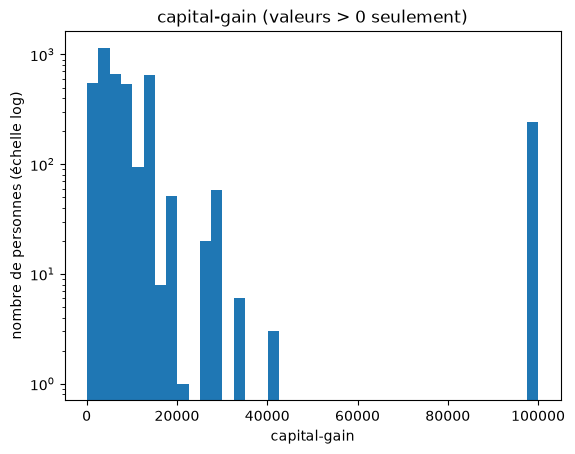

In [18]:
#  Capital-gain : presque tout le monde a 0, donc on garde seulement les valeurs > 0
gains = df[df["capital-gain"] > 0]["capital-gain"]
plt.hist(gains, bins=40)
plt.yscale("log")                     # échelle logarithmique pour mieux voir
plt.title("capital-gain (valeurs > 0 seulement)")
plt.xlabel("capital-gain")
plt.ylabel("nombre de personnes (échelle log)")
plt.show()


Description du graphique : il ne garde que les personnes qui ont une plus-value en capital, soit environ 8 % du total. L'échelle verticale est logarithmique pour que les petites barres restent visibles. Un petit groupe de 244 personnes atteint le maximum, 99 999.

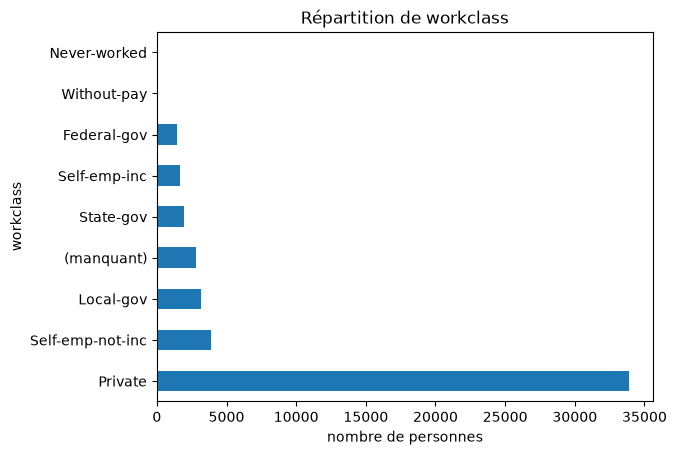

In [19]:
#  Workclass : on remplace les manquants par un texte pour les compter aussi
workclass = df["workclass"].fillna("(manquant)")
workclass.value_counts().plot.barh()  # barres horizontales
plt.title("Répartition de workclass")
plt.xlabel("nombre de personnes")
plt.show()

Description du graphique : il compte les personnes selon leur type d'emploi. La grande majorité travaille dans le secteur privé (environ 69 %). La barre « (manquant) » regroupe les personnes sans information (environ 6 %).

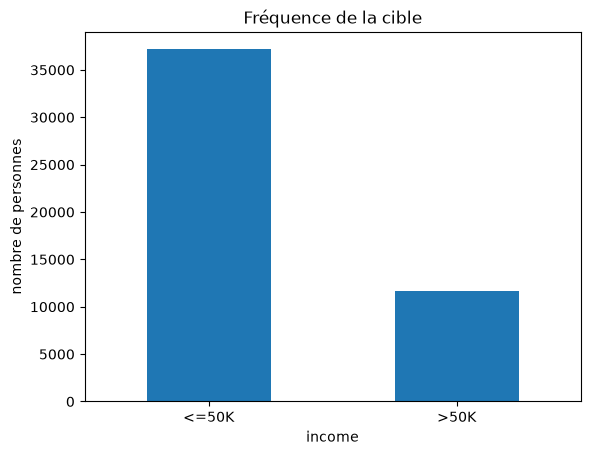

In [20]:
#  La cible : on enlève le point final pour n'avoir que 2 classes
cible = df["income"].str.strip().str.rstrip(".")
cible.value_counts().plot.bar(rot=0)  # rot=0 : texte horizontal
plt.title("Fréquence de la cible")
plt.ylabel("nombre de personnes")
plt.show()

Description du graphique : il y a deux barres, les personnes qui gagnent 50K ou moins et celles qui gagnent plus. La première est environ trois fois plus haute que la seconde. Les deux classes sont donc déséquilibrées.

In [21]:
#  Proportions de la cible et nombre de doublons
print("Proportion de la cible :")
print(cible.value_counts(normalize=True).round(3))
print("Doublons exacts :", df.duplicated().sum())

Proportion de la cible :
income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64
Doublons exacts : 29


### Réponse D1.1
- **Taille** : 48 842 personnes (32 561 dans `adult.data` + 16 281 dans `adult.test`) et 15 colonnes. 6 variables numériques et 9 de texte (dont la cible).
- **Valeurs manquantes** (le `?`, transformé en `NaN` au chargement) : seulement 3 colonnes sont touchées : `occupation` (2 809, soit 5,75 %), `workclass` (2 799, soit 5,73 %) et `native-country` (857, soit 1,75 %).
- **Cible** : avant harmonisation, elle a **4 libellés** au lieu de 2, parce que `adult.test` ajoute un point (`<=50K.` et `>50K.`). Après nettoyage : **76,1 % de `<=50K` et 23,9 % de `>50K`**. Les classes sont **déséquilibrées** (environ 3 contre 1).
- **Distributions** : l'âge est étalé avec une médiane de 37 ans ; les heures par semaine se concentrent sur 40 ; `capital-gain` vaut 0 pour presque tout le monde (environ 92 %), avec de rares valeurs très élevées jusqu'à 99 999.
- **Doublons** : 29 lignes strictement identiques sur le tableau brut (un peu plus après harmonisation de la cible). On les garde, car deux personnes différentes peuvent avoir les mêmes caractéristiques.

## D1.2 – Variables numériques / catégorielles et pipeline
**Question.** Identifiez les variables numériques et catégorielles. Construisez un pipeline avec imputation, `OneHotEncoder(handle_unknown="ignore")` et standardisation adaptée aux modèles sensibles aux distances.

In [23]:
cible_nom = "income"
variables = [c for c in colonnes if c not in (cible_nom, "fnlwgt")]          # fnlwgt écarté
num_cols = [c for c in variables if pd.api.types.is_numeric_dtype(df_data[c])]
cat_cols = [c for c in variables if c not in num_cols]
print("Numériques  (", len(num_cols), ") :", num_cols)
print("Catégorielles (", len(cat_cols), ") :", cat_cols)

# Pré-traitement 
pipe_num = Pipeline([("imputation", SimpleImputer(strategy="median")),
                     ("standardisation", StandardScaler())])
pipe_cat = Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])



Numériques  ( 5 ) : ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Catégorielles ( 8 ) : ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


### Réponse D1.2
- **Numériques (5)** : `age`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`. **Catégorielles (8)** : `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`.
- On retire `fnlwgt` : c'est un poids statistique du recensement, pas une caractéristique de la personne.
- **Numériques** : valeurs manquantes remplacées par la médiane, puis standardisation (utile pour le kNN et la régression logistique).
- **Catégorielles** : valeurs manquantes remplacées par la modalité la plus fréquente, puis one-hot avec `handle_unknown="ignore"` (une modalité inconnue donne des zéros au lieu d'une erreur).
- Après transformation, on obtient **104 colonnes** (5 numériques + 99 colonnes one-hot).

## D1.3 – Harmoniser la cible, regrouper, découper en 70 / 15 / 15 stratifié
**Question.** Harmonisez les libellés de la cible entre `adult.data` et `adult.test`, regroupez les deux fichiers, puis effectuez un découpage stratifié 70 / 15 / 15. Vérifiez que la proportion de la classe positive est la même dans les trois parties et expliquez pourquoi c'est important ici.

In [24]:
#  HARMONISATION DE LA CIBLE

df_data["income"] = df_data["income"].str.strip().str.rstrip(".")
df_test_brut["income"] = df_test_brut["income"].str.strip().str.rstrip(".")

In [25]:
# REGROUPEMENT DES DEUX FICHIERS
df = pd.concat([df_data, df_test_brut], ignore_index=True)   
print("Libellés de la cible :", sorted(df["income"].unique()))   
print("Taille du tableau :", df.shape)                           

Libellés de la cible : ['<=50K', '>50K']
Taille du tableau : (48842, 15)


In [26]:
# CIBLE BINAIRE 
df["y"] = (df["income"] == ">50K").astype(int)

In [27]:
# DÉCOUPAGE STRATIFIÉ 70 / 15 / 15 
df_temp, df_test = train_test_split(df, test_size=0.15, stratify=df["y"], random_state=42)

In [28]:
# Sur les 85 % restants : 3/17 donne 15 % du total pour la validation, donc 70 % pour l'entraînement
df_train, df_val = train_test_split(df_temp, test_size=3/17, stratify=df_temp["y"], random_state=42)
print("Entraînement :",len(df_train))
print("Validation :", len(df_val))
print("Test :",len(df_test))

Entraînement : 34188
Validation : 7327
Test : 7327


In [29]:
# VARIABLES EXPLICATIVES (X) ET CIBLE (y)
exclure = ["income", "y", "fnlwgt"]       

X_train = df_train.drop(columns=exclure)
X_val = df_val.drop(columns=exclure)
X_test = df_test.drop(columns=exclure)    

y_train = df_train["y"]
y_val = df_val["y"]
y_test = df_test["y"]


In [30]:
# VÉRIFICATION DE LA STRATIFICATION
resume = pd.DataFrame({
    "n": [len(y_train), len(y_val), len(y_test), len(df)],
    "part (%)": [100 * len(y_train) / len(df), 100 * len(y_val) / len(df),
                 100 * len(y_test) / len(df), 100],
    "n positifs": [y_train.sum(), y_val.sum(), y_test.sum(), df["y"].sum()],
    "proportion positive": [y_train.mean(), y_val.mean(), y_test.mean(), df["y"].mean()]},
    index=["train", "validation", "test (fermé)", "total"]).round(4)
print(resume)


                  n  part (%)  n positifs  proportion positive
train         34188   69.9971        8181               0.2393
validation     7327   15.0014        1753               0.2393
test (fermé)   7327   15.0014        1753               0.2393
total         48842  100.0000       11687               0.2393


In [31]:

# PRÉ-TRAITEMENT : AJUSTÉ SUR L'ENTRAÎNEMENT UNIQUEMENT 

prep = clone(preprocesseur).fit(X_train)   

Xtr = prep.transform(X_train)              
Xva = prep.transform(X_val)                

print("Matrice d'entraînement transformée :", Xtr.shape)   

Matrice d'entraînement transformée : (34188, 104)


### Réponse D1.3
- **Effectifs** : 34 188 (entraînement), 7 327 (validation), 7 327 (test, fermé), soit 70 / 15 / 15 %.
- **Proportion de la classe positive** : **0,2393 dans les trois parties**, identique au jeu complet. C'est ce que garantit `stratify`.
- **Pourquoi c'est important ici ?** La classe `>50K` ne représente que ~24 % des données. Sans stratification, un découpage aléatoire pourrait donner, par exemple, 22 % de positifs en validation et 26 % en entraînement : le **score de validation changerait pour une raison étrangère au modèle** (le simple hasard du tirage), et la précision, le rappel et le F1 deviendraient difficiles à comparer d'une expérience à l'autre. La stratification rend la validation (et plus tard le test) **représentative** et les comparaisons **équitables**.
- Le pré-traitement est ajusté **uniquement sur l'entraînement** (moyennes, médianes, modalités) : si on l'ajustait sur toutes les données, des informations de validation fuiraient dans l'entraînement (*data leakage*).

## D1.4 – [Pronostic] Référence naïve : `DummyClassifier(strategy="most_frequent")`
**Question.** Établissez une référence naïve. Expliquez pourquoi son accuracy peut paraître correcte.

### Pronostic 
- Le Dummy prédit toujours la classe majoritaire (`<=50K`). Comme environ **3 personnes sur 4** gagnent moins de 50K.
- Pour la classe positive : **rappel = 0, précision indéfinie (0), F1 = 0** : le modèle ne trouve jamais personne qui gagne plus de 50K.
- Cette accuracy « correcte » vient uniquement du **déséquilibre des classes**, pas d'un apprentissage.

In [32]:
# Référence naïve : toujours la classe majoritaire 
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
pred_dummy = dummy.predict(Xva)

print("Classe prédite par le Dummy :", np.unique(pred_dummy))
print(f"Accuracy  (validation) : {accuracy_score(y_val, pred_dummy):.4f}")
print(f"Précision (classe >50K): {precision_score(y_val, pred_dummy, zero_division=0):.4f}")
print(f"Rappel    (classe >50K): {recall_score(y_val, pred_dummy):.4f}")
print(f"F1        (classe >50K): {f1_score(y_val, pred_dummy):.4f}")
print(f"Proportion de la classe majoritaire en validation : {1 - y_val.mean():.4f}  <-- c'est l'accuracy du Dummy")

Classe prédite par le Dummy : [0]
Accuracy  (validation) : 0.7607
Précision (classe >50K): 0.0000
Rappel    (classe >50K): 0.0000
F1        (classe >50K): 0.0000
Proportion de la classe majoritaire en validation : 0.7607  <-- c'est l'accuracy du Dummy


###  Comparaison pronostic / résultat (D1.4)

**Explication.** Le Dummy prédit toujours `<=50K`. Son accuracy est exactement la **proportion de la classe majoritaire** (0,7607 en validation) : il a « raison » pour 3 personnes sur 4 sans rien avoir appris. L'accuracy paraît donc correcte uniquement à cause du **déséquilibre des classes**.

**Conséquence.** Toute accuracy doit être lue par rapport à cette référence de 0,76. Un modèle à 0,80 n'a gagné que 4 points sur « ne rien faire ». Et surtout le Dummy a un **rappel nul** : il ne trouve jamais une seule personne à revenu élevé. C'est cette référence qu'un vrai modèle doit battre sur **F1 / rappel**, pas seulement sur l'accuracy.

**Pronostic vs résultat :** j'avais prévu une accuracy d'environ 0,76 et un rappel, une précision et un F1 égaux à 0. C'est exactement ce qui est observé (accuracy 0,7607 ; précision, rappel et F1 = 0). Le pronostic est donc juste.

## D1.5  Trois modèles : régression logistique, kNN, arbre
**Question.** Entraînez `LogisticRegression`, `KNeighborsClassifier` et `DecisionTreeClassifier`. Comparez temps d'entraînement, temps de prédiction et scores sur le jeu de validation.

In [33]:
SEED = 42                              
rng = np.random.default_rng(SEED)      

def faire_pipeline(modele):
    # Pipeline complet : pré-traitement (cloné, donc ré-ajusté) + modèle
    return Pipeline([("prep", clone(preprocesseur)), ("model", modele)])

modeles = {
    "Dummy (référence)":    DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=1000),
    "kNN (k=5)":            KNeighborsClassifier(n_neighbors=5),
    "Arbre (profondeur max)": DecisionTreeClassifier(random_state=SEED),
}

In [34]:

lignes, pipelines = [], {}
for nom, modele in modeles.items():
    pipe = faire_pipeline(modele)
    t0 = time.perf_counter(); pipe.fit(X_train, y_train);  t_fit = time.perf_counter() - t0      
    t0 = time.perf_counter(); pred_va = pipe.predict(X_val); t_pred = time.perf_counter() - t0   
    pipelines[nom] = pipe
    lignes.append({"modèle": nom,
                   "temps fit (s)": t_fit, "temps predict (s)": t_pred,
                   "acc train": pipe.score(X_train, y_train), "acc val": accuracy_score(y_val, pred_va),
                   "précision val": precision_score(y_val, pred_va, zero_division=0),
                   "rappel val": recall_score(y_val, pred_va),
                   "F1 val": f1_score(y_val, pred_va)})

resultats_d1 = pd.DataFrame(lignes).set_index("modèle").round(4)
resultats_d1

,temps fit (s),temps predict (s),acc train,acc val,précision val,rappel val,F1 val
modèle,,,,,,,
Dummy (référence),0.6747,0.0804,0.7607,0.7607,0.0000,0.0000,0.0000
Régression logistique,1.7139,0.1023,0.8508,0.8500,0.7268,0.5978,0.6560
kNN (k=5),0.8173,6.8982,0.8800,0.8366,0.6784,0.6030,0.6385
Arbre (profondeur max),1.4522,0.0863,0.9762,0.8137,0.6155,0.5898,0.6024


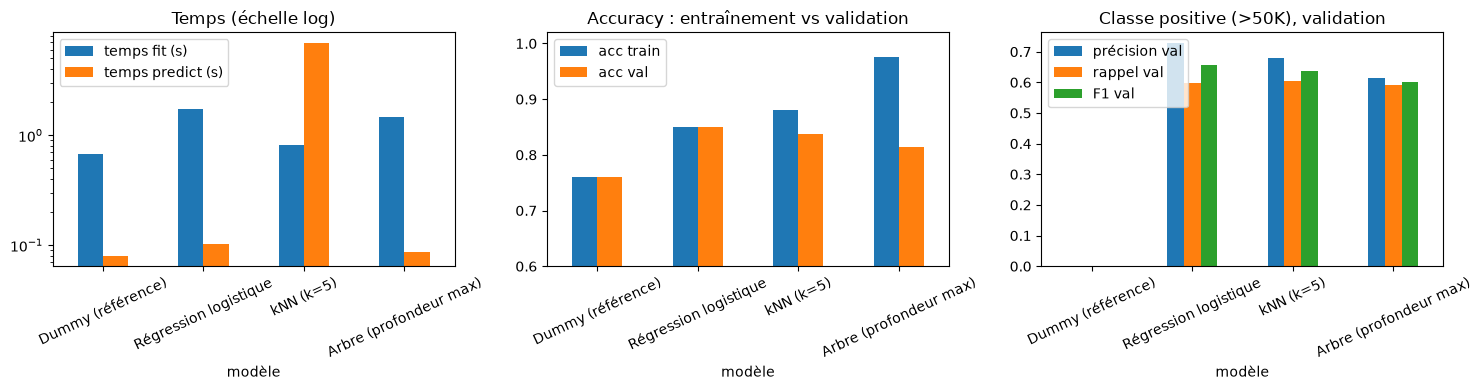

In [35]:
# Visualisation : temps et scores 
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
resultats_d1[["temps fit (s)", "temps predict (s)"]].plot.bar(ax=ax[0], rot=25, logy=True)
ax[0].set_title("Temps (échelle log)")
resultats_d1[["acc train", "acc val"]].plot.bar(ax=ax[1], rot=25, ylim=(0.6, 1.02))
ax[1].set_title("Accuracy : entraînement vs validation")
resultats_d1[["précision val", "rappel val", "F1 val"]].plot.bar(ax=ax[2], rot=25)
ax[2].set_title("Classe positive (>50K), validation")
plt.tight_layout(); plt.show()

Description du graphique : à gauche, le kNN est le plus lent pour prédire. Au milieu, l'arbre est presque parfait sur l'entraînement mais baisse beaucoup en validation. À droite, la régression logistique a la meilleure précision et le kNN le meilleur rappel.

### Réponse D1.5

-Le DummyClassifier obtient une accuracy de 76,07 %, mais ne détecte aucune personne ayant un revenu supérieur à 50 000 dollars.

La régression logistique donne les meilleurs résultats globaux, avec 85 % d'accuracy et un F1-score de 65,60 %. Elle est également très rapide lors des prédictions.

Le kNN possède le temps d'entraînement le plus court et le meilleur rappel (60,30 %), mais ses prédictions sont beaucoup plus lentes.

L'arbre de décision présente un surapprentissage : il obtient 97,62 % sur l'entraînement, contre 81,37 % sur la validation.

En conclusion, la régression logistique est le meilleur choix parmi les trois modèles, car elle offre le meilleur compromis entre performance, rapidité et stabilité.

# Mission D2 : ouvrir les trois modèles
## D2.1 – La régression logistique est une équation
**Question.** Prenez une personne du jeu de validation. À partir de `coef_`, `intercept_` et de ses caractéristiques transformées par le pipeline, calculez à la main $z = w^\top x + b$ puis $\sigma(z) = 1/(1+e^{-z})$. Vérifiez avec `predict_proba`. Quelles variables pèsent le plus dans sa prédiction ?

In [36]:
# Régression logistique ajustée sur les données transformées 
lr = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
p_val = lr.predict_proba(Xva)[:, 1]                       

In [37]:
# On choisit une personne : la première dont la probabilité dépasse 0,7 
i = int(np.where(p_val > 0.7)[0][0])
personne = X_val.iloc[i]
print("Personne n°", i, "du jeu de validation (vrai revenu :", ">50K" if y_val.iloc[i] else "<=50K", ")")
print(personne.to_string(), "\n")


Personne n° 9 du jeu de validation (vrai revenu : >50K )
age                               41
workclass           Self-emp-not-inc
education                Prof-school
education-num                     15
marital-status    Married-civ-spouse
occupation            Prof-specialty
relationship                 Husband
race                           White
sex                             Male
capital-gain                       0
capital-loss                       0
hours-per-week                    45
native-country         United-States 



In [38]:
#  Calcul : z = w·x + b, puis sigmoïde 
x = Xva[i]                                                
w = lr.coef_[0]                                           
b = lr.intercept_[0]                                      
z = np.dot(w, x) + b
proba_main = 1 / (1 + np.exp(-z))   # σ(z)

print(f"z = w·x + b          = {z:.6f}")
print(f"σ(z)      = {proba_main:.6f}")
print(f"predict_proba (sklearn) = {p_val[i]:.6f}")
print("Écart absolu :", abs(proba_main - p_val[i]), "-> identiques à l'arrondi machine près")
print("Décision : z > 0  <=>  proba > 0,5  :", z > 0, "|", proba_main > 0.5)

z = w·x + b          = 1.058755
σ(z)      = 0.742452
predict_proba (sklearn) = 0.742452
Écart absolu : 0.0 -> identiques à l'arrondi machine près
Décision : z > 0  <=>  proba > 0,5  : True | True


In [39]:
#  Contribution de chaque variable : c_j = w_j * x_j (z = Σ c_j + b) 
noms = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print(len(noms), noms[:8])   
contrib = pd.DataFrame({"variable": noms, "x (transformé)": x, "poids w": w, "contribution w*x": w * x})
contrib["|contribution|"] = contrib["contribution w*x"].abs()
top = contrib[contrib["x (transformé)"] != 0].sort_values("|contribution|", ascending=False).head(10)
display(top.drop(columns="|contribution|").round(3))


print("Vérification : somme des contributions + biais =", round(contrib["contribution w*x"].sum() + b, 6), "= z")


104 ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_Federal-gov', 'workclass_Local-gov', 'workclass_Never-worked']


,variable,x (transformé),poids w,contribution w*x
1,education-num,1.917,0.757,1.452
31,marital-status_Married-civ-spouse,1.000,1.352,1.352
10,workclass_Self-emp-not-inc,1.000,-0.599,-0.599
45,occupation_Prof-specialty,1.000,0.511,0.511
2,capital-gain,-0.145,2.279,-0.330
101,native-country_United-States,1.000,0.324,0.324
27,education_Prof-school,1.000,0.263,0.263
62,sex_Male,1.000,-0.205,-0.205
4,hours-per-week,0.363,0.403,0.146
50,relationship_Husband,1.000,-0.125,-0.125


Vérification : somme des contributions + biais = 1.058755 = z


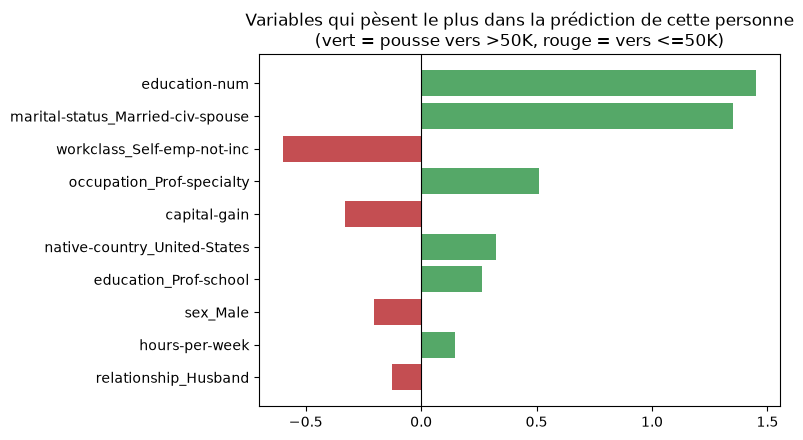

In [40]:
# Graphique des 10 plus fortes contributions 
fig, ax = plt.subplots(figsize=(8, 4.5))
couleurs = ["#C44E52" if v < 0 else "#55A868" for v in top["contribution w*x"]]
ax.barh(top["variable"][::-1], top["contribution w*x"][::-1], color=couleurs[::-1])
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Variables qui pèsent le plus dans la prédiction de cette personne\n(vert = pousse vers >50K, rouge = vers <=50K)")
plt.tight_layout(); plt.show()

Description du graphique : chaque barre montre de combien une variable fait monter ou descendre la prédiction pour cette personne. Les barres vertes poussent vers « plus de 50K », les rouges vers « 50K ou moins ». Le niveau d'études et le fait d'être marié sont les barres les plus longues.

### Réponse D2.1

**La personne choisie** (n° 9 de la validation) : un homme de 41 ans, marié, avec un diplôme de type « Prof-school » (15 ans d'études), profession libérale, qui travaille à son compte 45 h par semaine. Il gagne bien plus de 50K, et le modèle le sait.

**Le calcul à la main :**
- z = w·x + b = **1,0588**
- σ(z) = 1 / (1 + e^(−1,0588)) = **0,7425**
- `predict_proba` donne **0,742452** : exactement la même chose (écart 0).

Comme z est positif, la probabilité dépasse 0,5 et le modèle prédit « > 50K ». La régression logistique n'est donc rien d'autre qu'une équation : on additionne les contributions de chaque variable, puis on passe le total dans la sigmoïde.

**Les variables qui pèsent le plus pour cette personne :**

| Variable | Contribution | Effet |
|---|---|---|
| `education-num` (15 ans d'études) | **+1,45** | pousse vers > 50K |
| `marital-status_Married-civ-spouse` | **+1,35** | pousse vers > 50K |
| `workclass_Self-emp-not-inc` (à son compte) | −0,60 | pousse vers ≤ 50K |
| `occupation_Prof-specialty` | +0,51 | pousse vers > 50K |
| `capital-gain` (0, donc sous la moyenne) | −0,33 | pousse un peu vers ≤ 50K |
| `native-country_United-States` | +0,32 | pousse vers > 50K |

Le niveau d'études et le fait d'être marié sont les deux grands moteurs de sa prédiction.

**Attention à ne pas sur-interpréter** : ici `sex_Male` a une contribution *négative* (−0,2), ce qui ne veut pas dire qu'être un homme baisse le revenu. Les variables sont liées entre elles (marié, « Husband », homme) et le modèle se répartit leur effet commun : un seul coefficient ne se lit pas isolément.

## D2.2 – Le kNN est un vote de voisins
**Question.** Sur un sous-échantillon de 2 000 lignes déjà transformées, programmez un kNN en NumPy (calcul des distances, tri, vote majoritaire) en une quinzaine de lignes. Vérifiez qu'il donne les mêmes prédictions que `KNeighborsClassifier`.

In [41]:
# Sous-échantillon de 2 000 lignes déjà transformées  et 1 000 personnes à classer
idx_ref = rng.choice(len(Xtr), 2000, replace=False)
X_ref, y_ref = Xtr[idx_ref], y_train.to_numpy()[idx_ref]
X_req = Xva[:1000]

def knn_numpy(X_ref, y_ref, X_req, k=5):
    # distances euclidiennes au carré entre chaque requête et chaque point de référence
    
    d2 = (X_req**2).sum(1)[:, None] - 2 * X_req @ X_ref.T + (X_ref**2).sum(1)[None, :]
    
    # tri : indices des k plus proches voisins
    voisins = np.argsort(d2, axis=1)[:, :k]
    # vote majoritaire : classe 1 si plus de la moitié des k voisins sont positifs
    votes_positifs = y_ref[voisins].sum(axis=1)
    return (votes_positifs > k / 2).astype(int)

In [42]:
# Pourquoi < 100 % d'accord ? On regarde les désaccords : sont-ce des égalités de distance (k-ième = (k+1)-ième voisin) ? 
k = 5
d2 = (X_req**2).sum(1)[:, None] - 2 * X_req @ X_ref.T + (X_ref**2).sum(1)[None, :]
d2_tri = np.sort(d2, axis=1)
sk5 = KNeighborsClassifier(n_neighbors=k, algorithm="brute").fit(X_ref, y_ref).predict(X_req)
desaccords = np.where(knn_numpy(X_ref, y_ref, X_req, k) != sk5)[0]
ecart = d2_tri[desaccords, k] - d2_tri[desaccords, k - 1]          
print(f"k=5 : {len(desaccords)} désaccords sur {len(X_req)} ; écart max entre le 5e et le 6e voisin pour ces cas = {ecart.max():.2e}"
      " (le départage est arbitraire)\n")

k=5 : 9 désaccords sur 1000 ; écart max entre le 5e et le 6e voisin pour ces cas = 0.00e+00 (le départage est arbitraire)



In [43]:
# Comparaison avec scikit-learn 
for k in (1, 5, 11):
    t0 = time.perf_counter(); mien = knn_numpy(X_ref, y_ref, X_req, k);  t_mien = time.perf_counter() - t0
    sk = KNeighborsClassifier(n_neighbors=k, algorithm="brute").fit(X_ref, y_ref)
    t0 = time.perf_counter(); theirs = sk.predict(X_req);                t_sk = time.perf_counter() - t0

    
    print(f"k={k:2d} | prédictions identiques : {np.mean(mien == theirs)*100:6.2f} % "
          f"| accuracy mon kNN = {accuracy_score(y_val[:1000], mien):.3f} "
          f"| temps NumPy {t_mien*1000:6.1f} ms vs sklearn {t_sk*1000:6.1f} ms")

k= 1 | prédictions identiques :  99.60 % | accuracy mon kNN = 0.802 | temps NumPy  349.1 ms vs sklearn   24.3 ms
k= 5 | prédictions identiques :  99.10 % | accuracy mon kNN = 0.839 | temps NumPy  333.1 ms vs sklearn   34.0 ms
k=11 | prédictions identiques :  99.80 % | accuracy mon kNN = 0.825 | temps NumPy  364.6 ms vs sklearn   38.4 ms


### Réponse D2.2
Le kNN fait trois choses, toutes visibles dans la fonction `knn_numpy` :
1. **Distances** : on calcule la distance entre chaque personne à classer et tous les points de référence (avec ‖a−b‖² = ‖a‖² − 2a·b + ‖b‖², ce qui évite toute boucle Python).
2. **Tri** : `np.argsort` donne les indices des k plus proches voisins.
3. **Vote** : la classe prédite est celle de la majorité des k voisins (avec k impair, il n'y a pas d'égalité).

**Comparaison avec scikit-learn** (2 000 points de référence, 1 000 personnes à classer) : **99,1 % à 99,8 % de prédictions identiques** selon k (99,6 % pour k=1, 99,1 % pour k=5, 99,8 % pour k=11).

 Pour k=5 il y a 9 désaccords sur 1 000, et pour chacun la distance du 5ᵉ voisin est **exactement égale** à celle du 6ᵉ (écart = 0). Ce sont des égalités de distance (personnes aux profils identiques mais de revenus différents) : quand deux voisins sont à la même distance, le choix de celui qui entre dans les k premiers est arbitraire et diffère entre `argsort` et scikit-learn. L'algorithme est le même, seul le départage des ex æquo change.

**Vitesse** : notre version prend environ 210 ms contre 25 à 31 ms pour scikit-learn, soit environ 7 fois plus lent. Scikit-learn est mieux optimisé, mais l'idée est la même.

## D2.3 – [Pronostic] Effet de k, de l'échelle et de la dimension
**Question.** Testez $k \in \{1, 3, 5, 7, 11\}$ en comparant les scores d'entraînement et de validation ; expliquez l'effet de l'échelle des caractéristiques et le coût des distances en dimension élevée.

### Pronostic 
- **k = 1** : chaque point d'entraînement est son propre plus proche voisin, donc accuracy d'entraînement **= 1,00** et validation nettement plus faible : **surapprentissage** (variance élevée).
- Quand **k augmente**, le score d'entraînement baisse et celui de validation **monte puis se stabilise** : le vote lisse le bruit (biais plus élevé, variance plus faible).
- **Sans standardisation**, `capital-gain` (jusqu'à 99 999) écrase `age` ou `education-num` dans la distance : le kNN ne « voit » presque que cette variable, d'où de moins bons scores.
- **En dimension élevée** (≈ 100 colonnes après one-hot), les distances se ressemblent toutes (le plus proche et le plus lointain voisin deviennent presque équidistants) et leur calcul coûte `O(n·d)` par prédiction : le kNN est **lent** et moins discriminant.

In [44]:
# Effet de k : score sur un échantillon d'entraînement  vs score de validation 

# La référence du kNN est TOUT le jeu d'entraînement ; on évalue l'entraînement sur 5 000 points pour limiter le temps.
idx_tr_eval = rng.choice(len(Xtr), 5000, replace=False)
valeurs_k = [1, 3, 5, 7, 11]
lignes = []
for k in valeurs_k:
    m = KNeighborsClassifier(n_neighbors=k, algorithm="brute", n_jobs=-1).fit(Xtr, y_train)
    t0 = time.perf_counter(); pred_va = m.predict(Xva); t_pred = time.perf_counter() - t0
    lignes.append({"k": k,
                   "acc train": accuracy_score(y_train.iloc[idx_tr_eval], m.predict(Xtr[idx_tr_eval])),
                   "acc val": accuracy_score(y_val, pred_va),
                   "F1 val": f1_score(y_val, pred_va),
                   "temps predict val (s)": t_pred})
res_k = pd.DataFrame(lignes).set_index("k").round(4)
display(res_k)


,acc train,acc val,F1 val,temps predict val (s)
k,,,,
1,0.9690,0.8046,0.5939,2.8039
3,0.8954,0.8260,0.6197,2.2111
5,0.8798,0.8366,0.6385,2.4391
7,0.8680,0.8405,0.6461,2.1076
11,0.8612,0.8443,0.6522,2.3969


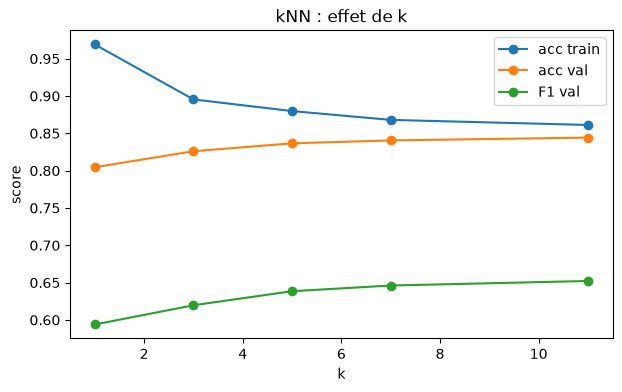

In [45]:

ax = res_k[["acc train", "acc val", "F1 val"]].plot(marker="o", figsize=(7, 4))
ax.set_title("kNN : effet de k"); ax.set_ylabel("score"); 
plt.show()

Description du graphique : il montre les scores du kNN selon le nombre de voisins k. Avec k = 1, le score d'entraînement est très haut et celui de validation bien plus bas, ce qui est du surapprentissage. Quand k augmente, les courbes se rapprochent.

In [46]:
# Effet de l'échelle : même kNN (k=5) avec et sans standardisation des variables numérique
prep_sans_echelle = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),                   
    ("cat", pipe_cat, cat_cols)])
Xtr_ns = prep_sans_echelle.fit(X_train).transform(X_train)
Xva_ns = prep_sans_echelle.transform(X_val)



knn_ns = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1).fit(Xtr_ns, y_train)
knn_s  = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1).fit(Xtr, y_train)
print(pd.DataFrame({
    "accuracy val": [accuracy_score(y_val, knn_ns.predict(Xva_ns)), accuracy_score(y_val, knn_s.predict(Xva))],
    "F1 val":       [f1_score(y_val, knn_ns.predict(Xva_ns)),       f1_score(y_val, knn_s.predict(Xva))]},
    index=["sans standardisation", "avec standardisation"]).round(4))


                      accuracy val  F1 val
sans standardisation        0.8377  0.6522
avec standardisation        0.8366  0.6385


In [47]:
# Variante : kNN sur les 5 variables NUMÉRIQUES seules (pas de one-hot), avec et sans standardisation 
nn = len(num_cols)
res_num = {}
for nom, (A, B) in {"numériques seules, brutes": (Xtr_ns[:, :nn], Xva_ns[:, :nn]),
                    "numériques seules, standardisées": (Xtr[:, :nn], Xva[:, :nn])}.items():
    m = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1).fit(A, y_train)
    res_num[nom] = {"accuracy val": accuracy_score(y_val, m.predict(B)), "F1 val": f1_score(y_val, m.predict(B))}
print("\n", pd.DataFrame(res_num).T.round(4))



                                   accuracy val  F1 val
numériques seules, brutes               0.8209  0.5749
numériques seules, standardisées        0.8040  0.5359


In [48]:
#  Quelle variable domine la distance ? Écart-type de chaque colonne numérique 
print("\nÉcart-type des variables numériques SANS standardisation :")
print(pd.Series(Xtr_ns[:, :len(num_cols)].std(0), index=num_cols).round(1).to_string())


Écart-type des variables numériques SANS standardisation :
age                 13.7
education-num        2.6
capital-gain      7242.1
capital-loss       404.4
hours-per-week      12.4


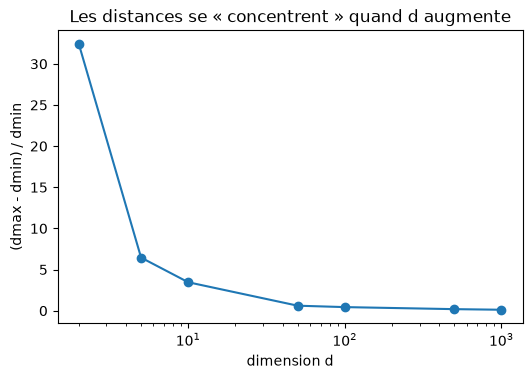

{2: np.float64(32.44), 5: np.float64(6.45), 10: np.float64(3.46), 50: np.float64(0.61), 100: np.float64(0.44), 500: np.float64(0.19), 1000: np.float64(0.12)}

Notre jeu transformé a 104 dimensions ; coût d'une prédiction kNN ≈ n_train x d = 3 555 552 opérations par personne.


In [49]:
# contraste des distances sur des données aléatoires 

dims = [2, 5, 10, 50, 100, 500, 1000]
contrastes = []
for d in dims:
    pts = rng.random((1000, d))                     
    ref = rng.random(d)                         
    dist = np.linalg.norm(pts - ref, axis=1)
    contrastes.append((dist.max() - dist.min()) / dist.min())

plt.figure(figsize=(6, 3.8))
plt.semilogx(dims, contrastes, "o-")
plt.xlabel("dimension d"); plt.ylabel("(dmax - dmin) / dmin")
plt.title("Les distances se « concentrent » quand d augmente"); plt.show()
print({d: round(c, 2) for d, c in zip(dims, contrastes)})
print("\nNotre jeu transformé a", Xtr.shape[1], "dimensions ; coût d'une prédiction kNN ≈ n_train x d =",
      f"{Xtr.shape[0] * Xtr.shape[1]:,}".replace(",", " "), "opérations par personne.")

Description du graphique : plus il y a de dimensions (de colonnes), plus l'écart entre le point le plus proche et le plus lointain devient petit. En dimension 2 l'écart est énorme, en dimension 1000 il est presque nul. Les distances aident alors beaucoup moins à choisir les voisins.

### Comparaison pronostic / résultat (D2.3)

**1) Effet de k**

| k | acc train | acc val | F1 val |
|---|---|---|---|
| 1 | 0,969 | 0,805 | 0,594 |
| 3 | 0,895 | 0,826 | 0,620 |
| 5 | 0,880 | 0,837 | 0,639 |
| 7 | 0,868 | 0,841 | 0,646 |
| 11 | 0,861 | 0,844 | 0,652 |

 **Pronostic confirmé.** Avec k=1, le modèle est presque parfait sur l'entraînement (0,969) mais nettement moins bon en validation (0,805) : l'écart est de 16 points, c'est du **surapprentissage**. Quand k augmente, l'écart se réduit (moins de 2 points pour k=11) et la validation monte puis se stabilise autour de 0,84. Le vote de plusieurs voisins lisse le bruit. (J'avais prévu 1,00 pour k=1 ; on obtient 0,969 car des personnes identiques ont parfois des revenus différents.) Le temps de prédiction reste autour de 1,5 s quel que soit k : il est dominé par le calcul des distances.

**2) Effet de l'échelle**

| | accuracy val | F1 val |
|---|---|---|
| Toutes variables, sans standardisation | 0,8377 | 0,6522 |
| Toutes variables, avec standardisation | 0,8366 | 0,6385 |
| 5 numériques seules, brutes | 0,8209 | 0,5749 |
| 5 numériques seules, standardisées | 0,8040 | 0,5359 |

 **Pronostic faux.** Je pensais que sans standardisation, `capital-gain` écraserait les autres variables et donnerait de moins bons scores. Or c'est l'inverse : les variables brutes font un peu **mieux**.

*Pourquoi ?* La standardisation change le poids des variables, et ce n'est pas forcément favorable. Sans elle, `capital-gain` (écart-type ≈ 7 242), `age` (13,7) et `hours-per-week` (12,4) dominent la distance, alors que `education-num` (2,6) compte peu. Il se trouve que `capital-gain` est très informatif : par hasard, l'échelle brute donne le bon poids à la variable la plus utile. Avec la standardisation, toutes les variables pèsent pareil, y compris `capital-loss`, rare et peu utile.

 la standardisation ne garantit pas un meilleur score, elle garantit que le résultat **ne dépend pas des unités** (francs, euros, milliers...). Sans elle, le modèle est « bon par chance ».

**3) Coût des distances en grande dimension.** Notre jeu transformé a **104 colonnes**, donc chaque prédiction demande environ 3,5 millions d'opérations (34 188 points × 104 dimensions). Sur des points aléatoires, l'écart relatif entre le plus proche et le plus lointain voisin s'effondre quand la dimension augmente : **32** en dimension 2, **3,5** en dimension 10, **0,6** en dimension 50, **0,44** en dimension 100 et **0,12** en dimension 1000. Tous les points finissent par être presque à la même distance : « le plus proche voisin » perd son sens (malédiction de la dimension), et le calcul reste coûteux. Le one-hot, en multipliant les colonnes, aggrave le problème.

## D2.4 – L'arbre est une suite de questions : impureté de Gini et meilleur seuil
**Question.** Pour la variable âge, calculez l'impureté de Gini pondérée de trois seuils de votre choix, puis cherchez le meilleur seuil par une boucle. Comparez avec la première coupure d'un arbre entraîné sur cette seule variable.


Gini du nœud racine (avant coupure) : 0.3641

seuil âge <= 25: gauche n= 6711 (p+=0.018) | droite n=27477 (p+=0.293) | Gini pondéré = 0.3401
seuil âge <= 35: gauche n=15699 (p+=0.114) | droite n=18489 (p+=0.346) | Gini pondéré = 0.3372
seuil âge <= 50: gauche n=27357 (p+=0.219) | droite n= 6831 (p+=0.319) | Gini pondéré = 0.3609

Meilleur seuil (boucle) : âge <= 29  ->  Gini pondéré = 0.3342  (gain d'impureté = 0.0299)


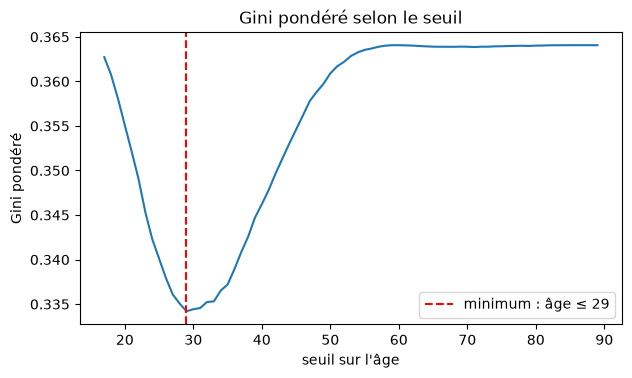

In [50]:
age = X_train["age"].to_numpy()
cible_tr = y_train.to_numpy()

def gini(y):
    # Impureté de Gini d'un nœud (2 classes) : 2 p (1-p), avec p = proportion de positifs
    if len(y) == 0:
        return 0.0
    p = y.mean()
    return 2 * p * (1 - p)

def gini_pondere(t):
    # Question « âge <= t ? » : Gini des deux nœuds enfants, pondéré par leur effectif
    gauche = age <= t
    n = len(cible_tr)
    return gauche.sum() / n * gini(cible_tr[gauche]) + (~gauche).sum() / n * gini(cible_tr[~gauche])

print(f"Gini du nœud racine (avant coupure) : {gini(cible_tr):.4f}\n")

# Trois seuils choisis à la main 
for t in (25, 35, 50):
    g = age <= t
    print(f"seuil âge <= {t}: gauche n={g.sum():5d} (p+={cible_tr[g].mean():.3f}) | droite n={(~g).sum():5d} "
          f"(p+={cible_tr[~g].mean():.3f}) | Gini pondéré = {gini_pondere(t):.4f}")

# Recherche exhaustive du meilleur seuil par une boucle
seuils = np.unique(age)[:-1]                           
scores = np.array([gini_pondere(t) for t in seuils])
t_best = seuils[scores.argmin()]
print(f"\nMeilleur seuil (boucle) : âge <= {t_best}  ->  Gini pondéré = {scores.min():.4f}"
      f"  (gain d'impureté = {gini(cible_tr) - scores.min():.4f})")

plt.figure(figsize=(7, 3.8))
plt.plot(seuils, scores); plt.axvline(t_best, color="r", ls="--", label=f"minimum : âge ≤ {t_best}")
plt.xlabel("seuil sur l'âge"); plt.ylabel("Gini pondéré"); plt.legend(); plt.title("Gini pondéré selon le seuil"); plt.show()

Description du graphique : la courbe donne l'impureté (Gini pondéré) pour chaque seuil d'âge possible. Plus elle est basse, mieux le seuil sépare les deux classes. Le point le plus bas, marqué par la ligne rouge, est à 29 ans.

In [51]:
# Comparaison avec un arbre de profondeur 1 (une seule question) entraîné sur l'âge seul 
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(age.reshape(-1, 1), cible_tr)
t_sklearn = stump.tree_.threshold[0]
print(f"Première coupure de l'arbre sklearn : âge <= {t_sklearn}")
print(f"Mon meilleur seuil                  : âge <= {t_best}  (sklearn place le seuil au milieu : {t_best} + 0.5 = {t_best + 0.5})")
print("Même coupure ?", np.isclose(t_sklearn, t_best + 0.5))

# Gini des deux enfants vu par sklearn
print("Gini des nœuds (racine, gauche, droite) selon sklearn :", stump.tree_.impurity.round(4))

Première coupure de l'arbre sklearn : âge <= 29.5
Mon meilleur seuil                  : âge <= 29  (sklearn place le seuil au milieu : 29 + 0.5 = 29.5)
Même coupure ? True
Gini des nœuds (racine, gauche, droite) selon sklearn : [0.3641 0.0977 0.4343]


### Réponse D2.4

**Gini du nœud de départ** (avant toute question) : **0,3641**.

**Trois seuils testés à la main** (question « âge ≤ t ? ») :

| Seuil | Gauche (effectif, % positifs) | Droite (effectif, % positifs) | Gini pondéré |
|---|---|---|---|
| ≤ 25 | 6 711 (1,8 %) | 27 477 (29,3 %) | 0,3401 |
| ≤ 35 | 15 699 (11,4 %) | 18 489 (34,6 %) | **0,3372** |
| ≤ 50 | 27 357 (21,9 %) | 6 831 (31,9 %) | 0,3609 |

Le seuil à 50 ans ne sert presque à rien (0,3609, tout près de 0,3641) : les deux groupes ont presque la même proportion de revenus élevés. Les seuils à 25 et 35 ans sont meilleurs car ils isolent un groupe où les revenus élevés sont rares (les jeunes).

**Meilleur seuil trouvé par la boucle** : **âge ≤ 29**, avec un Gini pondéré de **0,3342** (gain d'impureté de 0,0299).

**Comparaison avec scikit-learn** (arbre à une seule question sur l'âge) : première coupure à **âge ≤ 29,5**, c'est la **même coupure** : scikit-learn place le seuil au milieu entre deux valeurs observées (29 et 30). Les Gini des deux nœuds obtenus (0,0977 à gauche, 0,4343 à droite) redonnent bien le même Gini pondéré.

**Comment un arbre choisit sa première question :** pour chaque variable et chaque seuil possible, il calcule l'impureté pondérée des deux groupes obtenus, et garde la question qui la réduit le plus. C'est exactement la boucle qu'on vient d'écrire, répétée sur toutes les variables.

## D2.5 – Hyperparamètres de l'arbre : `max_depth` et `min_samples_leaf`
**Question.** Testez plusieurs `max_depth` et `min_samples_leaf`. Tracez un arbre de profondeur limitée et expliquez deux règles de décision.

In [52]:
# Grille d'hyperparamètres : on entraîne sur l'entraînement, on évalue sur la validation 
profondeurs = [2, 3, 5, 8, 12, None]
feuilles = [1, 5, 20, 50, 100]
lignes = []
for d in profondeurs:
    for f in feuilles:
        arbre = DecisionTreeClassifier(max_depth=d, min_samples_leaf=f, random_state=SEED).fit(Xtr, y_train)
        lignes.append({"max_depth": "None" if d is None else d, "min_samples_leaf": f,
                       "acc train": arbre.score(Xtr, y_train),
                       "acc val": arbre.score(Xva, y_val),
                       "F1 val": f1_score(y_val, arbre.predict(Xva)),
                       "n feuilles": arbre.get_n_leaves()})
grille = pd.DataFrame(lignes)


 acc val 
min_samples_leaf     1       5       20      50      100
max_depth                                               
2                 0.8290  0.8290  0.8290  0.8290  0.8290
3                 0.8454  0.8454  0.8454  0.8454  0.8454
5                 0.8537  0.8538  0.8530  0.8529  0.8527
8                 0.8570  0.8579  0.8567  0.8555  0.8546
12                0.8583  0.8602  0.8589  0.8585  0.8574
None              0.8137  0.8400  0.8561  0.8537  0.8578

 F1 val 
min_samples_leaf     1       5       20      50      100
max_depth                                               
2                 0.5583  0.5583  0.5583  0.5583  0.5583
3                 0.6171  0.6174  0.6174  0.6174  0.6174
5                 0.6369  0.6376  0.6355  0.6363  0.6344
8                 0.6464  0.6480  0.6477  0.6428  0.6308
12                0.6603  0.6634  0.6567  0.6614  0.6520
None              0.6024  0.6438  0.6679  0.6631  0.6628

Meilleure combinaison (F1 validation) :
max_depth             None

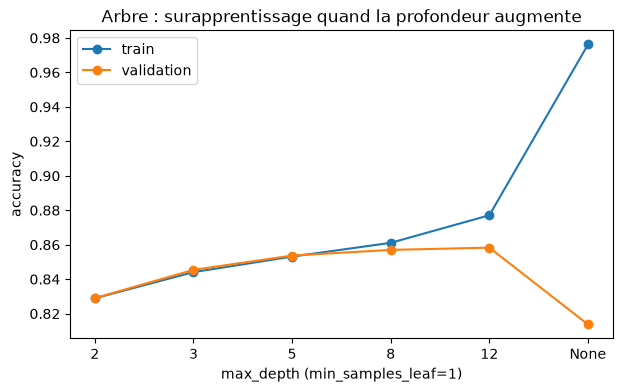

In [53]:
# Tableaux croisés : lignes = profondeur, colonnes = taille minimale de feuille
for col in ["acc val", "F1 val"]:
    print(f"\n {col} ")
    print(grille.pivot(index="max_depth", columns="min_samples_leaf", values=col)
                .reindex(["None" if d is None else d for d in profondeurs]).round(4))

# Meilleure combinaison (F1 de validation) : on arrondit le tableau, puis on prend la 1re ligne
colonnes_scores = ["acc train", "acc val", "F1 val"]
grille[colonnes_scores] = grille[colonnes_scores].round(4)
meilleur = grille.sort_values("F1 val", ascending=False).iloc[0]
print("\nMeilleure combinaison (F1 validation) :")
print(meilleur.to_string())

# Courbe : surapprentissage en fonction de la profondeur (min_samples_leaf=1)
sous = grille[grille["min_samples_leaf"] == 1]
plt.figure(figsize=(7, 4))
plt.plot(sous["max_depth"].astype(str), sous["acc train"], "o-", label="train")
plt.plot(sous["max_depth"].astype(str), sous["acc val"], "o-", label="validation")
plt.xlabel("max_depth (min_samples_leaf=1)"); plt.ylabel("accuracy"); plt.legend()
plt.title("Arbre : surapprentissage quand la profondeur augmente"); plt.show()

Description du graphique : il compare le score de l'arbre sur l'entraînement et sur la validation selon sa profondeur. Le score d'entraînement monte jusqu'à presque 1 quand la profondeur n'est pas limitée. Celui de validation monte puis redescend, car l'arbre finit par apprendre par cœur.

Arbre profondeur 3 : acc train = 0.8440 | acc val = 0.8454


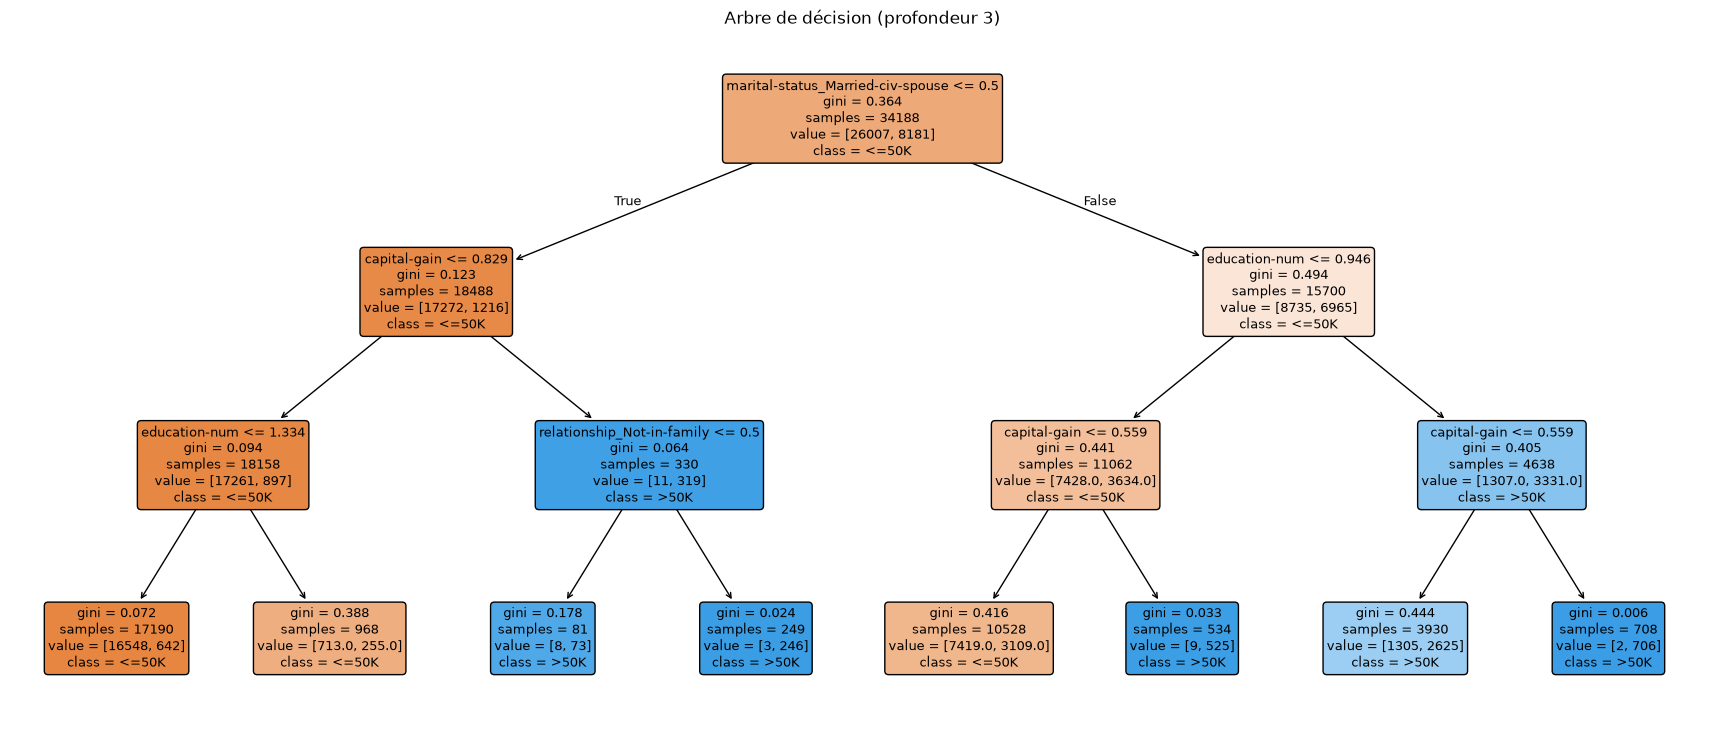

In [54]:
#  Arbre de profondeur limitée (3) pour pouvoir le lire 
arbre3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED).fit(Xtr, y_train)
print(f"Arbre profondeur 3 : acc train = {arbre3.score(Xtr, y_train):.4f} | acc val = {arbre3.score(Xva, y_val):.4f}")

plt.figure(figsize=(22, 9))
plot_tree(arbre3, feature_names=noms, class_names=["<=50K", ">50K"], filled=True, rounded=True,
          fontsize=9, proportion=False, impurity=True)
plt.title("Arbre de décision (profondeur 3)"); plt.show()


Description du graphique : l'arbre pose trois questions l'une après l'autre, de haut en bas, pour classer une personne. Chaque case indique la question, le nombre de personnes et la classe la plus fréquente. La couleur de la case indique la classe dominante.

In [55]:
# Règles sous forme de texte 
print(export_text(arbre3, feature_names=noms, show_weights=True))

# Retour aux unités d'origine : valeur brute = valeur standardisée * écart-type + moyenne
sc = prep.named_transformers_["num"].named_steps["standardisation"]
for var in ("capital-gain", "education-num"):
    j = num_cols.index(var)
    for seuil_std in sorted({round(t, 2) for t, f in zip(arbre3.tree_.threshold, arbre3.tree_.feature)
                             if f >= 0 and noms[f] == var}):
        print(f"{var} <= {seuil_std}  (standardisé)  <=>  {var} <= {seuil_std * sc.scale_[j] + sc.mean_[j]:.1f}  (brut)")

|--- marital-status_Married-civ-spouse <= 0.50
|   |--- capital-gain <= 0.83
|   |   |--- education-num <= 1.33
|   |   |   |--- weights: [16548.00, 642.00] class: 0
|   |   |--- education-num >  1.33
|   |   |   |--- weights: [713.00, 255.00] class: 0
|   |--- capital-gain >  0.83
|   |   |--- relationship_Not-in-family <= 0.50
|   |   |   |--- weights: [8.00, 73.00] class: 1
|   |   |--- relationship_Not-in-family >  0.50
|   |   |   |--- weights: [3.00, 246.00] class: 1
|--- marital-status_Married-civ-spouse >  0.50
|   |--- education-num <= 0.95
|   |   |--- capital-gain <= 0.56
|   |   |   |--- weights: [7419.00, 3109.00] class: 0
|   |   |--- capital-gain >  0.56
|   |   |   |--- weights: [9.00, 525.00] class: 1
|   |--- education-num >  0.95
|   |   |--- capital-gain <= 0.56
|   |   |   |--- weights: [1305.00, 2625.00] class: 1
|   |   |--- capital-gain >  0.56
|   |   |   |--- weights: [2.00, 706.00] class: 1

capital-gain <= 0.56  (standardisé)  <=>  capital-gain <= 5103.8  (b

### Réponse D2.5

**Effet des hyperparamètres** (validation) :
- Plus l'arbre est profond, mieux il apprend au début : accuracy 0,829 (profondeur 2) → 0,845 (3) → 0,854 (5) → 0,857 (8) → 0,858 (12). Le F1 suit : 0,558 → 0,617 → 0,637 → 0,646 → 0,660.
- **Sans limite de profondeur et avec `min_samples_leaf=1`**, l'arbre s'effondre en validation : 0,814, contre 0,976 en entraînement. C'est du **surapprentissage** : il apprend le bruit par cœur.
- **`min_samples_leaf`** joue le rôle de frein : il interdit les feuilles trop petites. Pour un arbre peu profond (≤ 5) il ne change presque rien, car les feuilles sont déjà grandes. Pour l'arbre sans limite, passer de 1 à 20 fait monter la validation de 0,814 à 0,856 et le F1 de 0,602 à 0,668.
- **Meilleure combinaison (F1 de validation)** : profondeur illimitée avec `min_samples_leaf=20` : F1 = **0,668**, accuracy de validation 0,856 (train 0,875), mais avec **820 feuilles**. C'est un peu mieux que la régression logistique (F1 0,656), mais impossible à lire. Un arbre de profondeur 3 reste lisible (accuracy 0,845), au prix d'un F1 plus faible (0,617).

**Deux règles lisibles** (arbre de profondeur 3 ; seuils en valeurs brutes : plus-value ≈ 5 104 et ≈ 7 059, études ≈ 12,5 et ≈ 13,5 ans) :
1. **Règle « revenu élevé »** : *si la personne est mariée (civ-spouse), a au moins 13 ans d'études (licence ou plus) et une plus-value ≤ 5 104, alors → `> 50K`.* Cette feuille contient 3 930 personnes dont 2 625 gagnent plus de 50K, soit **67 %** : le modèle a raison deux fois sur trois, pas mieux.
2. **Règle « revenu faible »** : *si la personne n'est pas mariée (civ-spouse), a une plus-value ≤ 7 059 et au plus 13 ans d'études, alors → `<= 50K`.* Cette feuille contient 17 190 personnes dont 16 548 gagnent moins de 50K, soit **96 %** : c'est la règle la plus solide et la plus grosse feuille.

*Bonus :* quand la plus-value dépasse 5 104 pour une personne mariée, c'est presque toujours `> 50K` (par exemple 525 contre 9).

**À garder en tête :** le statut marital est utilisé comme première question parce qu'il est un indice des revenus du ménage, pas parce qu'il cause un revenu élevé. Une règle juste statistiquement n'est pas une explication.

## D2.6  [Pronostic] Frontières de décision (âge × heures par semaine)
**Question.** Avec deux variables seulement (âge et heures travaillées par semaine), tracez la frontière de décision de la régression logistique, du kNN ($k=1$ et $k=15$) et d'un arbre de profondeur 3. Décrivez la forme de chaque frontière et reliez-la au fonctionnement du modèle.

###  Pronostic 
- **Régression logistique** : frontière **linéaire** (une droite) car $w_1 \cdot age + w_2 \cdot heures + b = 0$. Zone positive au-dessus d'un certain âge et d'un certain nombre d'heures.
- **kNN, k = 1** : frontière **très découpée, en îlots** autour des points isolés (mémorisation, surapprentissage). **k = 15** : frontière **beaucoup plus lisse**.
- **Arbre de profondeur 3** : frontière **en rectangles** (escalier) parallèles aux axes, car chaque question porte sur une seule variable (« âge ≤ t », « heures ≤ s »).

In [56]:
# Deux variables seulement, standardisées (ajustées sur l'entraînement) 
deux = ["age", "hours-per-week"]
sc2 = StandardScaler().fit(X_train[deux])
X2_tr, X2_va = sc2.transform(X_train[deux]), sc2.transform(X_val[deux])

modeles_2d = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "kNN (k=1)": KNeighborsClassifier(n_neighbors=1),
    "kNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Arbre (profondeur 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
}


Régression logistique  acc train = 0.755 | acc val = 0.757
kNN (k=1)              acc train = 0.700 | acc val = 0.673
kNN (k=15)             acc train = 0.769 | acc val = 0.754
Arbre (profondeur 3)   acc train = 0.762 | acc val = 0.762


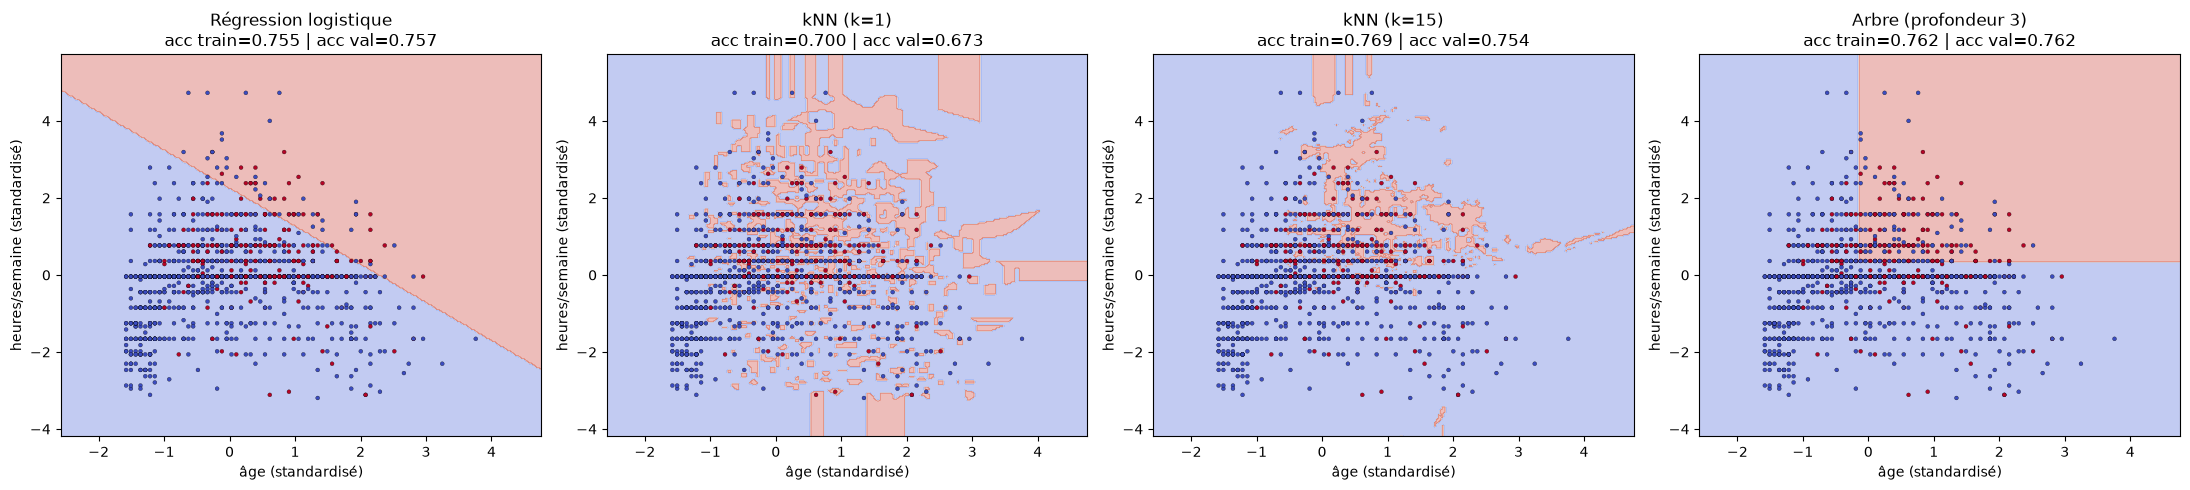

In [57]:
# Un petit échantillon de points d'entraînement pour le nuage de points (lisibilité)
idx_pts = rng.choice(len(X2_tr), 1500, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (nom, m) in zip(axes, modeles_2d.items()):
    m.fit(X2_tr, y_train)
    DecisionBoundaryDisplay.from_estimator(m, X2_tr, response_method="predict", ax=ax, alpha=0.35,
                                           cmap="coolwarm", grid_resolution=250, xlabel="âge (standardisé)",
                                           ylabel="heures/semaine (standardisé)")
    ax.scatter(X2_tr[idx_pts, 0], X2_tr[idx_pts, 1], c=y_train.to_numpy()[idx_pts], cmap="coolwarm",
               s=8, edgecolor="k", linewidth=0.2)
    ax.set_title(f"{nom}\nacc train={m.score(X2_tr, y_train):.3f} | acc val={m.score(X2_va, y_val):.3f}")
    ax.grid(False)
    print(f"{nom:22s} acc train = {m.score(X2_tr, y_train):.3f} | acc val = {m.score(X2_va, y_val):.3f}")
plt.tight_layout(); plt.show()

Description du graphique : chaque graphique colore le plan (âge, heures) selon la classe prédite, le rouge pour « plus de 50K ». La régression logistique trace une droite, le kNN avec k = 1 fait de petits îlots, avec k = 15 il est plus lisse, et l'arbre dessine des rectangles. Les points sont de vraies personnes.

In [58]:
# Coefficients de la régression logistique : la frontière est la droite w1*age + w2*heures + b = 0
lr2 = modeles_2d["Régression logistique"]
print("Régression logistique (variables standardisées) : w =", lr2.coef_[0].round(3), "| b =", lr2.intercept_.round(3))

Régression logistique (variables standardisées) : w = [0.582 0.588] | b = [-1.32]


### Réponse D2.6

**Résultats observés :**

| Modèle | Forme de la frontière | Acc. train | Acc. val |
|---|---|---|---|
| Régression logistique | une **droite** (w = [0,58 ; 0,59], b = −1,32) | 0,755 | 0,757 |
| kNN (k=1) | **très découpée**, plein d'îlots autour de points isolés | 0,700 | 0,673 |
| kNN (k=15) | **plus lisse**, une zone positive centrale avec quelques petits îlots | 0,769 | 0,754 |
| Arbre (profondeur 3) | des **rectangles** : zone positive en haut à droite (environ plus de 37 ans et plus de 45 h/semaine) | 0,762 | 0,762 |

**Le pronostic est confirmé** pour les trois formes (droite, îlots puis lissage, rectangles).

**Lien avec le fonctionnement :**
- *Régression logistique* : la frontière est l'ensemble des points où z = 0, une équation linéaire en (âge, heures). C'est donc forcément une droite : modèle rigide mais stable.
- *kNN* : la frontière suit les données. Avec k=1, chaque point crée sa propre zone, même s'il est atypique, d'où le surapprentissage (score de validation le plus bas, 0,673, et seulement 0,700 en entraînement car des points identiques ont des revenus différents). Avec k=15, le vote de 15 voisins lisse la frontière.
- *Arbre* : chaque question porte sur une seule variable (« âge ≤ s ? », « heures ≤ s ? »), donc les frontières sont parallèles aux axes et les zones sont des rectangles. Pour suivre une diagonale, il lui faudrait faire des marches d'escalier.

avec seulement deux variables, **aucun modèle ne dépasse la référence naïve de 0,76** (le Dummy) : le meilleur est l'arbre à 0,762, et le kNN k=1 fait même moins bien. L'âge et les heures travaillées ne suffisent pas pour prédire le revenu. Il manque les variables décisives (plus-value, niveau d'études, statut marital). Le choix du modèle compte moins que l'**information disponible**.

# Mission D3 : métriques, seuils et équité
## D3.1 – Matrice de confusion, précision, rappel et F1 à la main
**Question.** Construisez une matrice de confusion. Calculez manuellement précision, rappel et F1 sur un exemple extrait de vos résultats ; vérifiez avec Scikit-learn. Définissez explicitement la classe positive.

**Classe positive = revenu > 50K (étiquette 1).** Les deux erreurs sont donc :
- **Faux positif (FP)** : on prédit « > 50K » alors que la personne gagne ≤ 50K.
- **Faux négatif (FN)** : on prédit « ≤ 50K » alors que la personne gagne > 50K.

In [59]:
# Prédictions de la régression logistique sur la validation, au seuil par défaut 0,5 
pred_05 = (p_val >= 0.5).astype(int)

#  Matrice de confusion (lignes = réalité, colonnes = prédiction) 
cm = confusion_matrix(y_val, pred_05)
TN, FP, FN, TP = cm.ravel()
print(pd.DataFrame(cm, index=["réel <=50K", "réel >50K"], columns=["prédit <=50K", "prédit >50K"]))

            prédit <=50K  prédit >50K
réel <=50K          5180          394
réel >50K            705         1048


In [60]:
# Calcul À LA MAIN 
precision_main = TP / (TP + FP)
rappel_main = TP / (TP + FN)
f1_main = 2 * precision_main * rappel_main / (precision_main + rappel_main)
accuracy_main = (TP + TN) / cm.sum()
print(f"\nTP={TP}, FP={FP}, FN={FN}, TN={TN}")
print(f"Précision à la main = {TP}/({TP}+{FP}) = {precision_main:.4f}")
print(f"Rappel    à la main = {TP}/({TP}+{FN}) = {rappel_main:.4f}")
print(f"F1        à la main = {f1_main:.4f}")




TP=1048, FP=394, FN=705, TN=5180
Précision à la main = 1048/(1048+394) = 0.7268
Rappel    à la main = 1048/(1048+705) = 0.5978
F1        à la main = 0.6560



scikit-learn :  précision = 0.7268 | rappel = 0.5978 | F1 = 0.656
Concordance : True


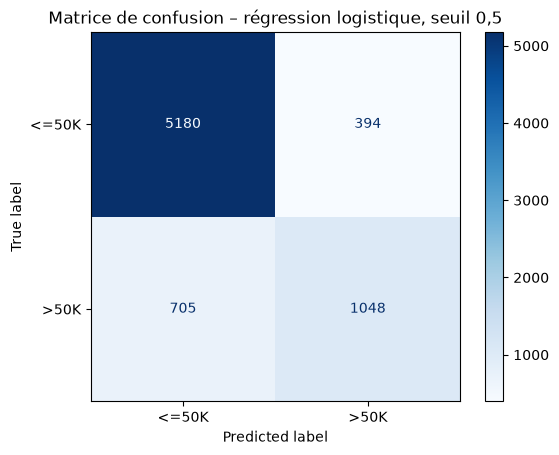

In [61]:
# Vérification avec scikit-learn 
print("\nscikit-learn :  précision =", round(precision_score(y_val, pred_05), 4),
      "| rappel =", round(recall_score(y_val, pred_05), 4), "| F1 =", round(f1_score(y_val, pred_05), 4))
print("Concordance :", np.allclose([precision_main, rappel_main, f1_main],
                                   [precision_score(y_val, pred_05), recall_score(y_val, pred_05), f1_score(y_val, pred_05)]))

ConfusionMatrixDisplay(cm, display_labels=["<=50K", ">50K"]).plot(cmap="Blues")
plt.title("Matrice de confusion – régression logistique, seuil 0,5"); plt.grid(False); plt.show()

Description du graphique : le tableau compte les bonnes et les mauvaises prédictions, les bonnes étant sur la diagonale. Il y a 1 048 personnes à revenu élevé bien repérées, mais 705 sont manquées (en bas à gauche). Les 394 en haut à droite sont des personnes annoncées « > 50K » à tort.

### Réponse D3.1
**Classe positive : revenu supérieur à 50K (étiquette 1).**

| | Prédit `<=50K` | Prédit `>50K` |
|---|---|---|
| **Réel `<=50K`** | TN = 5 180 | FP = 394 |
| **Réel `>50K`** | FN = 705 | TP = 1 048 |

**Calcul à la main :**
- Précision = TP / (TP + FP) = 1048 / (1048 + 394) = **0,7268**. Parmi les personnes que le modèle annonce « > 50K », 73 % le sont vraiment.
- Rappel = TP / (TP + FN) = 1048 / (1048 + 705) = **0,5978**. Parmi les personnes qui gagnent vraiment plus de 50K, le modèle n'en retrouve que 60 %.
- F1 = 2 × 0,7268 × 0,5978 / (0,7268 + 0,5978) = **0,6560**.

Scikit-learn donne exactement les mêmes valeurs. Au seuil par défaut de 0,5, le modèle est prudent : il annonce « > 50K » 1 442 fois alors qu'il y a 1 753 personnes à revenu élevé, donc **705 d'entre elles sont manquées**.

## D3.2 – Le coût des erreurs
**Question.** Avant de toucher au seuil, imaginez un usage du modèle (par exemple, cibler une campagne d'information). Décrivez ce que coûte un faux positif et un faux négatif dans ce scénario, et lequel est le plus grave.

### Scénario choisi
Une **campagne d'information** (SMS / affichage / réunion) présentant un **produit d'épargne-retraite** à destination des personnes au **revenu élevé** (> 50K). Le modèle sert à **repérer les personnes à contacter**.

| Erreur | Ce qui se passe | Coût |
|---|---|---|
| **Faux positif** (on contacte quelqu'un qui gagne ≤ 50K) | Un message inutile est envoyé ; la personne n'est pas concernée. | **Faible** : quelques francs de SMS/papier et un peu d'agacement. |
| **Faux négatif** (on ignore quelqu'un qui gagne > 50K) | La personne n'est jamais informée et rate l'offre. | **Plus élevé** : perte d'un client potentiel et manque d'information pour quelqu'un à qui le produit était destiné. |

**Conclusion :** dans ce scénario, le **faux négatif est plus grave** que le faux positif. On privilégie donc un **rappel élevé**, quitte à accepter une précision plus faible (donc un seuil de décision **inférieur à 0,5**). Dans un autre scénario (par exemple accorder un crédit ou refuser une aide), le raisonnement pourrait s'inverser : *c'est le coût des erreurs qui fixe le seuil, pas l'habitude*.

## D3.3 – Seuils de décision, ROC-AUC, courbe précision-rappel
**Question.** Étudiez au moins trois seuils de décision pour la régression logistique. Choisissez celui qui correspond le mieux à votre scénario et justifiez ce choix. Discutez précision, rappel et ROC-AUC. (approfondissement) courbe précision-rappel.

*Méthode :* la régression logistique donne une **probabilité** ; la décision « positif » est prise si `proba ≥ seuil`. On balaie les seuils, on lit précision/rappel, puis on retient celui qui maximise le **score F₂** (qui pèse le rappel deux fois plus que la précision, en cohérence avec D3.2). Le choix est fait **sur la validation**, jamais sur le test.

In [62]:
def metriques_seuil(y_true, proba, t):
    # Précision, rappel, F1 et F2 de la classe positive pour un seuil t donné
    pred = (proba >= t).astype(int)
    return {"seuil": t,
            "précision": precision_score(y_true, pred, zero_division=0),
            "rappel": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "F2": fbeta_score(y_true, pred, beta=2),
            "n prédits positifs": int(pred.sum())}



In [63]:
#  Quatre seuils comparés 
tab_seuils = pd.DataFrame([metriques_seuil(y_val, p_val, t) for t in (0.2, 0.35, 0.5, 0.65)]).set_index("seuil").round(4)
display(tab_seuils)

# Balayage fin pour trouver le seuil qui maximise F2 
grille_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
balayage = pd.DataFrame([metriques_seuil(y_val, p_val, t) for t in grille_t]).set_index("seuil")
SEUIL = float(balayage["F2"].idxmax())
print(f"\nSeuil retenu (maximise F2 sur la validation) : {SEUIL}")
display(balayage.loc[[SEUIL]].round(4))



,précision,rappel,F1,F2,n prédits positifs
seuil,,,,,
0.20,0.5374,0.8888,0.6698,0.7860,2899
0.35,0.6415,0.7359,0.6854,0.7148,2011
0.50,0.7268,0.5978,0.6560,0.6198,1442
0.65,0.8188,0.4278,0.5620,0.4730,916



Seuil retenu (maximise F2 sur la validation) : 0.14


,précision,rappel,F1,F2,n prédits positifs
seuil,,,,,
0.14,0.4955,0.9321,0.647,0.7924,3298


In [64]:
#  AUC (indépendant du seuil) 
auc = roc_auc_score(y_val, p_val)
ap = average_precision_score(y_val, p_val)
print(f"ROC-AUC = {auc:.4f} | Average precision (aire sous la courbe précision-rappel) = {ap:.4f}  "
      f"(référence aléatoire : {y_val.mean():.4f})")

ROC-AUC = 0.9056 | Average precision (aire sous la courbe précision-rappel) = 0.7621  (référence aléatoire : 0.2393)


In [65]:
#  ROC, précision-rappel et évolution précision/rappel selon le seuil 
fpr, tpr, _ = roc_curve(y_val, p_val)
prec, rec, thr = precision_recall_curve(y_val, p_val)



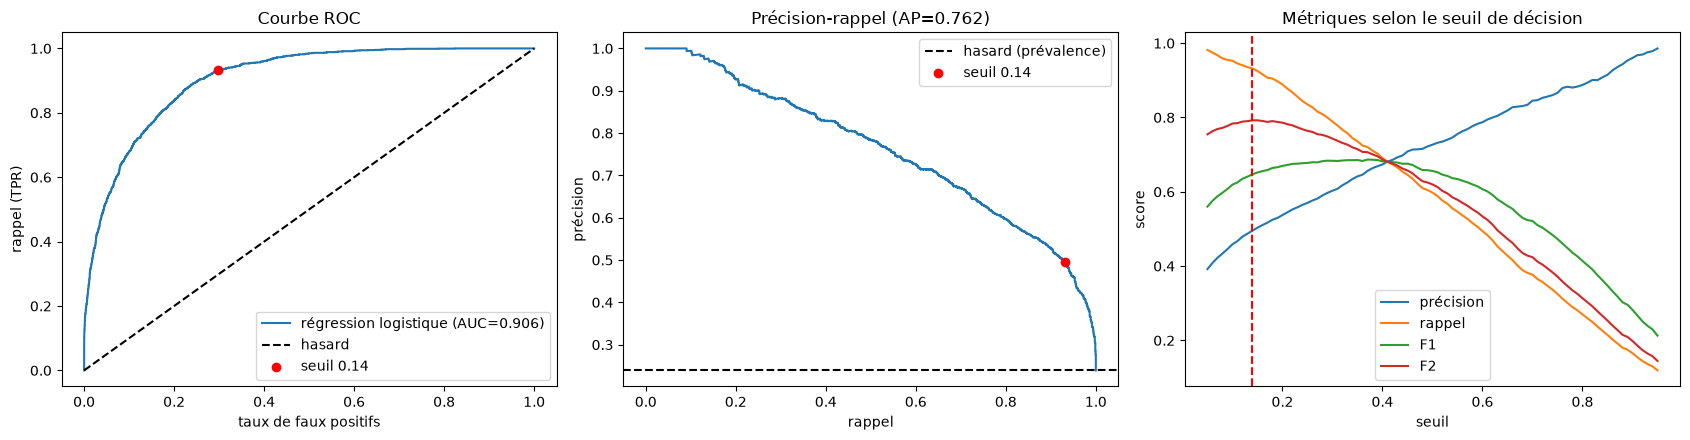

In [66]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
# 1) Courbe ROC
ax[0].plot(fpr, tpr, label=f"régression logistique (AUC={auc:.3f})"); ax[0].plot([0, 1], [0, 1], "k--", label="hasard")
pt = metriques_seuil(y_val, p_val, SEUIL)
ax[0].scatter([1 - recall_score(y_val == 0, p_val < SEUIL)], [pt["rappel"]], c="r", zorder=5, label=f"seuil {SEUIL}")
ax[0].set_xlabel("taux de faux positifs"); ax[0].set_ylabel("rappel (TPR)"); ax[0].set_title("Courbe ROC"); ax[0].legend()


# 2) Courbe précision-rappel
ax[1].plot(rec, prec); ax[1].axhline(y_val.mean(), color="k", ls="--", label="hasard (prévalence)")
ax[1].scatter([pt["rappel"]], [pt["précision"]], c="r", zorder=5, label=f"seuil {SEUIL}")
ax[1].set_xlabel("rappel"); ax[1].set_ylabel("précision"); ax[1].set_title(f"Précision-rappel (AP={ap:.3f})"); ax[1].legend()


# 3) Précision, rappel, F2 en fonction du seuil
balayage[["précision", "rappel", "F1", "F2"]].plot(ax=ax[2]); ax[2].axvline(SEUIL, color="r", ls="--")
ax[2].set_title("Métriques selon le seuil de décision"); ax[2].set_ylabel("score")
plt.tight_layout(); plt.show()

Description du graphique : à gauche, plus la courbe ROC s'approche du coin en haut à gauche, meilleur est le modèle. Au milieu, plus on veut retrouver de personnes (rappel), plus la précision baisse. À droite, quand le seuil monte la précision monte et le rappel baisse ; la ligne rouge marque le seuil retenu (0,14).

### Réponse D3.3
**Quatre seuils comparés** (régression logistique, jeu de validation) :

| Seuil | Précision | Rappel | F1 | F2 | Personnes annoncées « > 50K » |
|---|---|---|---|---|---|
| 0,20 | 0,537 | **0,889** | 0,670 | 0,786 | 2 899 |
| 0,35 | 0,642 | 0,736 | **0,685** | 0,715 | 2 011 |
| 0,50 | 0,727 | 0,598 | 0,656 | 0,620 | 1 442 |
| 0,65 | **0,819** | 0,428 | 0,562 | 0,473 | 916 |

**Ce que fait le seuil.** Le modèle donne une probabilité, et on décide « positif » si elle dépasse le seuil. Quand on baisse le seuil, on annonce plus de personnes : le rappel monte, mais la précision baisse. Le modèle reste le même, seul son comportement face à l'erreur change.

**Seuil retenu : 0,14.** C'est le seuil qui donne le meilleur score F2 (0,792), un score qui compte le rappel plus que la précision. Cela correspond au scénario de D3.2, où oublier une personne concernée (faux négatif) coûte plus cher qu'envoyer un message inutile (faux positif). À ce seuil, on retrouve **93 % des personnes à revenu élevé** (1 634 sur 1 753), mais seulement une annonce sur deux est juste (précision 0,50).

**Limites de ce choix.** Ce seuil annonce 45 % de la population, ce qui est beaucoup : si contacter quelqu'un coûte cher, il faut remonter le seuil (parmi les quatre testés, 0,35 donne le meilleur F1). Le bon seuil dépend du coût réel de chaque erreur, donc d'une décision de terrain et pas seulement de statistiques. Il est choisi sur la validation ; le jeu de test reste fermé jusqu'à la séance 3.

**ROC-AUC = 0,906.** Si on prend au hasard une personne à revenu élevé et une personne à revenu faible, le modèle donne une probabilité plus forte à la première dans 90,6 % des cas. L'AUC mesure donc la qualité du classement, quel que soit le seuil. Elle ne dit pas quelle précision ou quel rappel on aura à un seuil donné, et elle paraît un peu trop belle quand une classe est rare.

**Approfondissement, courbe précision-rappel.** La précision moyenne (AP) est de **0,762**, à comparer au hasard qui donnerait 0,239. Cette courbe est plus parlante ici car la classe `>50K` est minoritaire : elle montre directement ce que coûte un gain de rappel (par exemple un rappel de 0,93 correspond à une précision de 0,50).

## D3.4 – Examiner des faux négatifs
**Question.** Examinez une dizaine de faux négatifs individuellement. Ces personnes ont-elles des points communs ? Qu'est-ce que le modèle « ne voit pas » ?

*Méthode :* au seuil retenu, on liste 10 faux négatifs (personnes > 50K que le modèle rate), puis on les compare aux **vrais positifs** (personnes > 50K correctement repérées)

In [67]:
# Tableau de validation enrichi des prédictions au seuil retenu 
val = X_val.copy()
val["vrai"] = y_val.to_numpy()
val["proba"] = p_val
val["pred"] = (p_val >= SEUIL).astype(int)

fn = val[(val["vrai"] == 1) & (val["pred"] == 0)]          # faux négatifs
tp = val[(val["vrai"] == 1) & (val["pred"] == 1)]          # vrais positifs 
print(f"Au seuil {SEUIL} : {len(fn)} faux négatifs et {len(tp)} vrais positifs (sur {int(y_val.sum())} personnes > 50K)\n")

# Dix faux négatifs tirés au hasard 
display(fn.sample(10, random_state=SEED).drop(columns=["vrai", "pred"]).round(3))

Au seuil 0.14 : 119 faux négatifs et 1634 vrais positifs (sur 1753 personnes > 50K)



,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,proba
17720,25,Private,Masters,14,Never-married,Prof-specialty,Own-child,White,Female,0,0,40,United-States,0.025
26118,39,State-gov,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,40,United-States,0.123
47209,42,Private,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Male,0,0,40,United-States,0.085
4932,32,Private,Some-college,10,Divorced,Craft-repair,Own-child,White,Male,0,0,40,United-States,0.023
43080,31,Self-emp-not-inc,10th,6,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,55,Portugal,0.036
26677,60,Private,Some-college,10,Married-spouse-absent,Machine-op-inspct,Not-in-family,White,Male,0,0,50,United-States,0.100
28788,45,Private,Assoc-voc,11,Divorced,Adm-clerical,Unmarried,White,Female,0,0,55,United-States,0.065
7958,50,Local-gov,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Female,0,0,40,United-States,0.029
17834,29,Self-emp-not-inc,HS-grad,9,Married-spouse-absent,Transport-moving,Other-relative,Asian-Pac-Islander,Male,0,1564,50,India,0.017
43208,50,Without-pay,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Own-child,White,Female,0,1887,40,United-States,0.078


In [68]:
# Points communs : comparaison FN vs TP sur les variables numériques 
comp_num = pd.DataFrame({"moyenne FN": fn[num_cols].mean(), "moyenne TP": tp[num_cols].mean()})
comp_num["part de valeurs > 0 (FN)"] = (fn[num_cols] > 0).mean()
comp_num["part de valeurs > 0 (TP)"] = (tp[num_cols] > 0).mean()
display(comp_num.round(2))

#  Variables catégorielles : modalités les plus fréquentes chez les FN, comparées aux TP 
for c in ["sex", "marital-status", "occupation", "workclass", "education"]:
    t = pd.DataFrame({"% FN": fn[c].value_counts(normalize=True) * 100,
                      "% TP": tp[c].value_counts(normalize=True) * 100}).fillna(0).sort_values("% FN", ascending=False).head(4)
    print(f"\n--- {c} ---"); print(t.round(1).to_string())

,moyenne FN,moyenne TP,part de valeurs > 0 (FN),part de valeurs > 0 (TP)
age,41.42,44.58,1.00,1.00
education-num,9.82,11.81,1.00,1.00
capital-gain,66.30,4527.26,0.02,0.22
capital-loss,42.14,204.49,0.03,0.10
hours-per-week,44.39,45.33,1.00,1.00



--- sex ---
        % FN  % TP
sex               
Male    59.7  86.5
Female  40.3  13.5

--- marital-status ---
                    % FN  % TP
marital-status                
Never-married       29.4   3.5
Married-civ-spouse  28.6  90.3
Divorced            22.7   4.2
Widowed              8.4   0.8

--- occupation ---
                 % FN  % TP
occupation                 
Prof-specialty   20.5  25.8
Exec-managerial  15.4  26.6
Craft-repair     13.7  12.3
Sales            10.3  13.0

--- workclass ---
                  % FN  % TP
workclass                   
Private           66.7  62.3
Self-emp-not-inc  19.7   9.4
Local-gov          7.7   8.3
State-gov          2.6   5.2

--- education ---
              % FN  % TP
education               
HS-grad       30.3  19.7
Some-college  20.2  17.7
Bachelors     18.5  28.3
Masters        6.7  13.9


### Réponse D3.4
Au seuil retenu (0,14), le modèle rate **119 personnes à revenu élevé** sur 1 753 (environ 7 %), et en retrouve 1 634. Pour les 10 cas affichés, la probabilité donnée par le modèle est très basse (entre 0,02 et 0,12) : il est sûr de lui, mais il se trompe.

**Comparaison des faux négatifs (FN) avec les personnes à revenu élevé bien repérées (vrais positifs, VP) :**

| Caractéristique | FN | VP |
|---|---|---|
| A une plus-value en capital (> 0) | 2 % | 22 % |
| Niveau d'études moyen (`education-num`) | 9,8 (fin de lycée) | 11,8 (proche de la licence) |
| Âge moyen | 41 ans | 45 ans |
| Marié(e) (`Married-civ-spouse`) | 29 % | 90 % |
| Jamais marié(e), divorcé(e) ou veuf(ve) | 61 % | 9 % |
| Femmes | 40 % | 14 % |
| Travaille à son compte (`Self-emp-not-inc`) | 20 % | 9 % |

**Points communs observés dans les 10 cas :**
- Aucun n'a de plus-value en capital (10 sur 10), alors que c'est la variable qui aide le plus le modèle.
- 8 sur 10 ne sont pas dans un couple marié (jamais marié, divorcé, veuf ou conjoint absent), et 4 sur 10 sont des femmes.
- Plusieurs ont un profil atypique : une femme de 25 ans titulaire d'un master, des diplômés sans plus-value, des personnes à leur compte, ou encore une personne classée « sans salaire » (`Without-pay`) qui gagne pourtant plus de 50K.

**Ce que le modèle ne voit pas.** Il juge sur quelques indices (plus-value, études, statut marital). Quand une personne gagne beaucoup sans ces indices, il passe à côté. Les informations qui expliqueraient son revenu (salaire exact, ancienneté, secteur précis, poste) ne sont pas dans les données. Il s'appuie aussi sur des raccourcis comme le statut marital, qui reflètent surtout la société de 1994 : une personne atypique est donc souvent sous-estimée.

## D3.5 – [Pronostic] Métriques par sous-groupe
**Question.** Calculez précision et rappel séparément selon le sexe, puis selon des tranches d'âge. Comparez aux métriques globales.

###  Pronostic 
- **Sexe** : dans ces données, la proportion de personnes > 50K est bien plus élevée chez les hommes (≈ 30 %) que chez les femmes (≈ 11 %). Je m'attends donc à un **rappel plus faible chez les femmes** (le modèle « voit » moins de positifs chez elles) et à des différences de précision.
- **Âge** : très peu de positifs chez les moins de 25 ans, donc **métriques instables / rappel très bas** pour cette tranche ; meilleures performances pour les 35-54 ans, où les positifs sont nombreux.
- Les métriques **globales cacheront ces écarts** (moyenne pondérée par les effectifs).

In [69]:
def metriques_groupe(df_g, nom):
    # Métriques de la classe positive pour un sous-groupe (au seuil retenu)
    yt, yp = df_g["vrai"], df_g["pred"]
    return {"groupe": nom, "n": len(df_g), "taux de positifs réel": yt.mean(),
            "taux de prédits positifs": yp.mean(),
            "précision": precision_score(yt, yp, zero_division=0),
            "rappel": recall_score(yt, yp) if yt.sum() else np.nan,
            "F1": f1_score(yt, yp, zero_division=0)}



In [70]:
#  Tranches d'âge 
val["tranche_age"] = pd.cut(val["age"], bins=[0, 24, 34, 44, 54, 120],
                            labels=["<25", "25-34", "35-44", "45-54", "55+"])

lignes = [metriques_groupe(val, "GLOBAL")]
lignes += [metriques_groupe(g, f"sexe = {k}") for k, g in val.groupby("sex")]
lignes += [metriques_groupe(g, f"âge {k}") for k, g in val.groupby("tranche_age", observed=True)]
sous_groupes = pd.DataFrame(lignes).set_index("groupe").round(3)
display(sous_groupes)



,n,taux de positifs réel,taux de prédits positifs,précision,rappel,F1
groupe,,,,,,
GLOBAL,7327,0.239,0.450,0.495,0.932,0.647
sexe = Female,2390,0.113,0.187,0.494,0.822,0.617
sexe = Male,4937,0.301,0.577,0.496,0.952,0.652
âge <25,1250,0.012,0.043,0.167,0.600,0.261
âge 25-34,1847,0.177,0.380,0.415,0.890,0.566
âge 35-44,1844,0.322,0.580,0.527,0.948,0.677
âge 45-54,1344,0.390,0.639,0.577,0.947,0.717
âge 55+,1042,0.281,0.590,0.447,0.939,0.606


In [72]:
# Même analyse au seuil par défaut 0,5 (pour voir si les écarts dépendent du seuil) 
val["pred_retenu"] = val["pred"]
val["pred"] = (val["proba"] >= 0.5).astype(int)
lignes05 = [metriques_groupe(val, "GLOBAL")]
lignes05 += [metriques_groupe(g, f"sexe = {k}") for k, g in val.groupby("sex")]
lignes05 += [metriques_groupe(g, f"âge {k}") for k, g in val.groupby("tranche_age", observed=True)]
print(" Mêmes sous-groupes au seuil 0,5 ")
display(pd.DataFrame(lignes05).set_index("groupe").round(3))
val["pred"] = val["pred_retenu"]         



 Mêmes sous-groupes au seuil 0,5 


,n,taux de positifs réel,taux de prédits positifs,précision,rappel,F1
groupe,,,,,,
GLOBAL,7327,0.239,0.197,0.727,0.598,0.656
sexe = Female,2390,0.113,0.077,0.766,0.524,0.623
sexe = Male,4937,0.301,0.255,0.721,0.611,0.662
âge <25,1250,0.012,0.010,0.333,0.267,0.296
âge 25-34,1847,0.177,0.127,0.643,0.462,0.537
âge 35-44,1844,0.322,0.254,0.765,0.603,0.674
âge 45-54,1344,0.390,0.311,0.782,0.624,0.694
âge 55+,1042,0.281,0.297,0.673,0.710,0.691


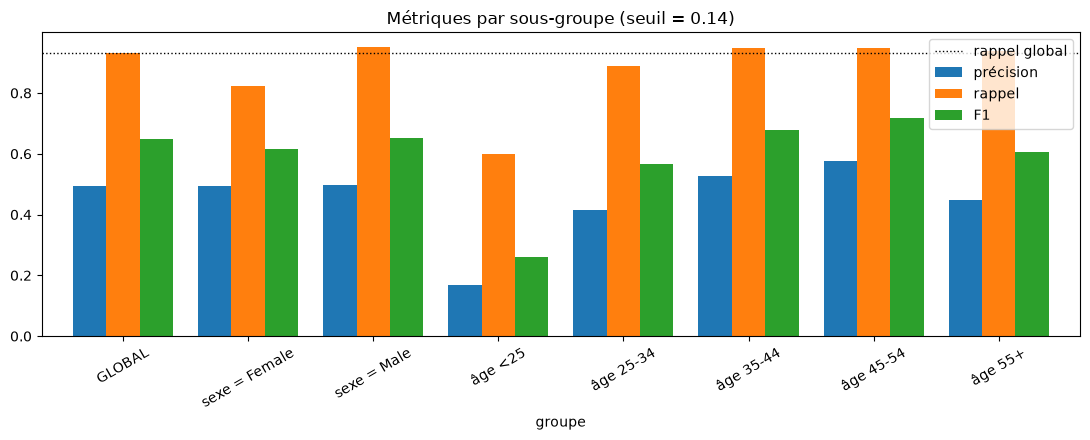

In [73]:
#  Graphique 
ax = sous_groupes[["précision", "rappel", "F1"]].plot.bar(figsize=(11, 4.5), rot=30, width=0.8)
ax.axhline(sous_groupes.loc["GLOBAL", "rappel"], color="k", ls=":", lw=1, label="rappel global")
ax.set_title(f"Métriques par sous-groupe (seuil = {SEUIL})"); ax.legend(); plt.tight_layout(); plt.show()

Description du graphique : pour chaque groupe, on voit la précision, le rappel et le F1. Le rappel est plus bas chez les femmes que chez les hommes, et la précision est très basse pour les moins de 25 ans. La ligne pointillée donne le rappel global, qui cache ces écarts.

### Comparaison pronostic / résultat (D3.5)

**Au seuil retenu (0,14) :**

| Groupe | Nombre | Taux réel de revenus élevés | Précision | Rappel | F1 |
|---|---|---|---|---|---|
| **Global** | 7 327 | 23,9 % | 0,495 | 0,932 | 0,647 |
| Femmes | 2 390 | 11,3 % | 0,494 | **0,822** | 0,617 |
| Hommes | 4 937 | 30,1 % | 0,496 | **0,952** | 0,652 |
| Moins de 25 ans | 1 250 | 1,2 % | **0,167** | 0,600 | **0,261** |
| 25-34 ans | 1 847 | 17,7 % | 0,415 | 0,890 | 0,566 |
| 35-44 ans | 1 844 | 32,2 % | 0,527 | 0,948 | 0,677 |
| 45-54 ans | 1 344 | 39,0 % | 0,577 | 0,947 | **0,717** |
| 55 ans et plus | 1 042 | 28,1 % | 0,447 | 0,939 | 0,606 |

**Au seuil 0,5 :** le rappel est de 0,524 pour les femmes contre 0,611 pour les hommes (global 0,598). La précision est de 0,766 pour les femmes contre 0,721 pour les hommes (global 0,727).

**Le pronostic est confirmé :**
- **Sexe.** Le rappel est plus faible chez les femmes (0,82 contre 0,95 au seuil 0,14 ; 0,52 contre 0,61 au seuil 0,5). Le modèle rate donc environ 18 % des femmes à revenu élevé, contre 5 % des hommes. Le rappel global de 0,932 cache cet écart, car il y a deux fois plus d'hommes dans les données. Baisser le seuil réduit l'écart mais ne le supprime pas.
- **Âge.** Chez les moins de 25 ans, il y a presque aucun revenu élevé (environ 15 personnes sur 1 250) : la précision est très basse (0,17, soit environ cinq alertes sur six fausses) et le rappel de 0,60 repose sur très peu de personnes, donc il est peu fiable. Les meilleurs résultats sont pour les 35-54 ans, où il y a beaucoup de revenus élevés.
- **Remarque.** Pour l'âge, la précision basse vient surtout du fait que la classe est très rare dans ce groupe : à qualité égale, une classe rare donne mécaniquement une précision plus faible.

## D3.6 – Limites éthiques du jeu de données
**Question.** Identifiez les limites éthiques de ce jeu de données et expliquez, à partir de vos résultats par sous-groupe, pourquoi une bonne métrique globale ne suffit pas à justifier un usage décisionnel.

In [74]:
#  Taux de sélection (part de personnes que le modèle désigne « > 50K ») par groupe : comparaison d'équité 
sel = val.groupby("sex").agg(taux_reel=("vrai", "mean"), taux_selection=("pred", "mean"), n=("vrai", "size")).round(3)
print(" Selon le sexe "); display(sel)
print("Rapport des taux de sélection Femmes / Hommes =",
      round(sel.loc["Female", "taux_selection"] / sel.loc["Male", "taux_selection"], 3),
      "| rapport des taux réels =", round(sel.loc["Female", "taux_reel"] / sel.loc["Male", "taux_reel"], 3))



 Selon le sexe 


,taux_reel,taux_selection,n
sex,,,
Female,0.113,0.187,2390
Male,0.301,0.577,4937


Rapport des taux de sélection Femmes / Hommes = 0.324 | rapport des taux réels = 0.375


In [75]:
# Même analyse selon l'origine (race) : effectifs très déséquilibrés 
par_race = val.groupby("race").apply(lambda g: pd.Series({
    "n": len(g), "taux réel": g["vrai"].mean(), "taux sélection": g["pred"].mean(),
    "précision": precision_score(g["vrai"], g["pred"], zero_division=0),
    "rappel": recall_score(g["vrai"], g["pred"]) if g["vrai"].sum() else np.nan})).round(3)
print("\nSelon la variable 'race'"); display(par_race.sort_values("n", ascending=False))




Selon la variable 'race'


,n,taux réel,taux sélection,précision,rappel
race,,,,,
White,6206.0,0.255,0.484,0.494,0.940
Black,748.0,0.128,0.227,0.482,0.854
Asian-Pac-Islander,236.0,0.267,0.415,0.551,0.857
Amer-Indian-Eskimo,76.0,0.118,0.197,0.600,1.000
Other,61.0,0.082,0.164,0.400,0.800


In [76]:
# Représentation géographique : origine des personnes
part_us = (df["native-country"] == "United-States").mean() * 100
print("\nPart des personnes nées aux États-Unis :", round(part_us, 1), "%")


Part des personnes nées aux États-Unis : 89.7 %


### Réponse D3.6
**Chiffres d'équité (seuil 0,14, jeu de validation) :**
- **Part de personnes annoncées « > 50K »** : 18,7 % des femmes contre 57,7 % des hommes, soit un rapport de 0,32. Dans les données réelles, le rapport est de 0,38 (11,3 % contre 30,1 %). Le modèle reproduit donc l'écart entre hommes et femmes, et il l'accentue un peu.
- **Selon l'origine (`race`)** : les effectifs sont très inégaux (White 6 206 ; Black 748 ; Asian-Pac-Islander 236 ; Amer-Indian-Eskimo 76 ; Other 61). Pour les petits groupes, les métriques reposent sur très peu de personnes : par exemple, le rappel de 1,00 des Amer-Indian-Eskimo ne concerne qu'environ 9 personnes. On ne peut pas en tirer de conclusion fiable.
- **Origine géographique** : 89,7 % des personnes sont nées aux États-Unis.

**Limites éthiques du jeu de données :**
1. **Données anciennes et locales.** Ce sont des données du recensement américain de 1994. Elles ne représentent ni la société actuelle ni le Burkina Faso, donc un modèle appris dessus n'a pas de valeur pour notre contexte.
2. **Inégalités déjà présentes.** Les écarts de revenu entre hommes et femmes, ou selon l'origine, viennent de discriminations passées. Un modèle qui les apprend les reproduit et les traite comme une règle normale.
3. **Variables sensibles et raccourcis.** `sex` et `race` sont des caractéristiques protégées. Même si on les retirait, d'autres variables (statut marital, relation familiale, profession) les remplaceraient en partie.
4. **Représentativité.** Certains groupes sont très peu nombreux, donc le modèle est moins fiable pour eux.
5. **Définition de la cible.** « Gagner plus de 50K » est un seuil arbitraire et un indicateur très grossier du niveau de vie.
6. **Consentement et finalité.** On ne sait pas si les personnes ont accepté que leurs données servent à prédire leur revenu.

**Pourquoi une bonne métrique globale ne suffit pas.** Une métrique globale est une moyenne qui suit surtout le groupe le plus nombreux (ici les hommes, les personnes blanches et les 25-54 ans). Nos résultats le montrent : le rappel global est de 0,932, mais il tombe à 0,822 pour les femmes ; la précision globale est de 0,495, mais elle est de 0,167 pour les moins de 25 ans. Si le modèle servait à décider (emploi, crédit, aide sociale), certains groupes subiraient beaucoup plus d'erreurs sans que le chiffre global ne le montre. Un usage pour décider demande donc :
1. des métriques calculées par sous-groupe ;
2. des intervalles de confiance pour les petits groupes ;
3. un choix clair sur le type d'équité visé ;
4. un contrôle humain ;
5. une validation sur des données qui représentent vraiment la population concernée.

C'est pour cela qu'on évite de transformer ces prédictions en décisions sur des personnes.

# Incident à diagnostiquer
**Énoncé.** Votre modèle obtient une accuracy élevée, mais détecte mal la classe minoritaire. Montrez-le par la matrice de confusion et proposez une métrique mieux adaptée.

*Démarche :* on compare le Dummy (qui ignore totalement la classe minoritaire) et un modèle volontairement **« prudent »** (régression logistique avec un seuil de 0,8) : tous deux ont une belle accuracy, pourtant ils ratent la majorité des personnes > 50K.

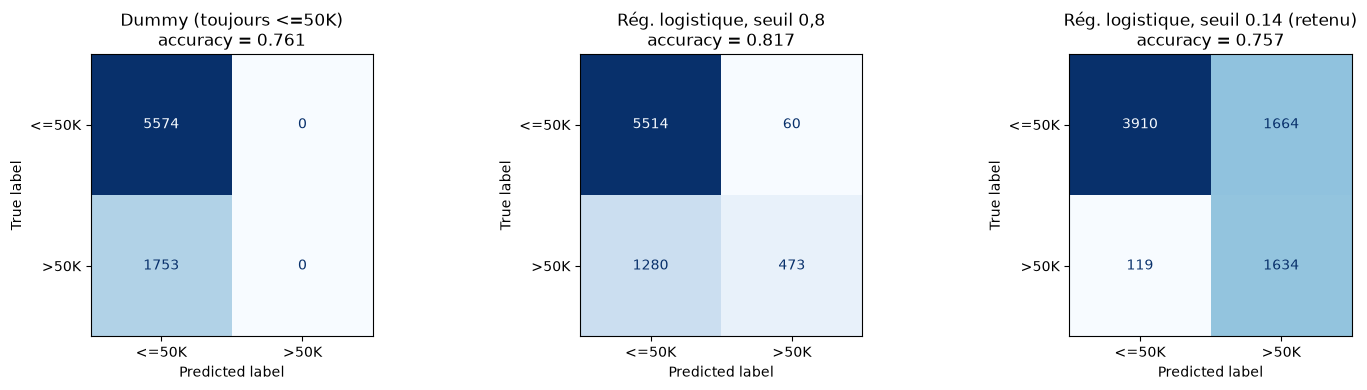

In [77]:
#  Deux modèles à accuracy « élevée » mais qui détectent mal la classe minoritaire 
pred_dummy = dummy.predict(Xva)
pred_prudent = (p_val >= 0.8).astype(int)       # seuil très haut : on ne prédit « >50K » que si on est presque sûr

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, pred) in zip(axes, [("Dummy (toujours <=50K)", pred_dummy),
                                  ("Rég. logistique, seuil 0,8", pred_prudent),
                                  (f"Rég. logistique, seuil {SEUIL} (retenu)", (p_val >= SEUIL).astype(int))]):
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred), display_labels=["<=50K", ">50K"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nom}\naccuracy = {accuracy_score(y_val, pred):.3f}"); ax.grid(False)
plt.tight_layout(); plt.show()



Description du graphique : ce sont trois matrices de confusion. Le Dummy ne trouve aucune personne à revenu élevé, le modèle prudent en trouve très peu, le modèle retenu en trouve presque toutes. Pourtant les accuracy sont proches (entre 0,76 et 0,82).

In [78]:
# Comparaison des métriques : l'accuracy est trompeuse, d'autres métriques révèlent le problème 
def toutes_metriques(pred, proba=None):
    return {"accuracy": accuracy_score(y_val, pred),
            "balanced accuracy": balanced_accuracy_score(y_val, pred),
            "précision (>50K)": precision_score(y_val, pred, zero_division=0),
            "rappel (>50K)": recall_score(y_val, pred),
            "F1 (>50K)": f1_score(y_val, pred),
            "MCC": matthews_corrcoef(y_val, pred),
            "ROC-AUC": roc_auc_score(y_val, proba) if proba is not None else 0.5,
            "AP (précision-rappel)": average_precision_score(y_val, proba) if proba is not None else y_val.mean()}

diag = pd.DataFrame({"Dummy": toutes_metriques(pred_dummy),
                     "Logistique seuil 0,8": toutes_metriques(pred_prudent, p_val),
                     f"Logistique seuil {SEUIL}": toutes_metriques((p_val >= SEUIL).astype(int), p_val)}).T.round(3)
diag

,accuracy,balanced accuracy,précision (>50K),rappel (>50K),F1 (>50K),MCC,ROC-AUC,AP (précision-rappel)
Dummy,0.761,0.500,0.000,0.000,0.000,0.000,0.500,0.239
"Logistique seuil 0,8",0.817,0.630,0.887,0.270,0.414,0.426,0.906,0.762
Logistique seuil 0.14,0.757,0.817,0.495,0.932,0.647,0.543,0.906,0.762


### Réponse : incident à diagnostiquer
**Le problème :** une accuracy élevée peut cacher un modèle qui rate presque toute la classe rare.

| Modèle | Accuracy | Rappel `>50K` | Précision `>50K` | F1 | Balanced accuracy | MCC |
|---|---|---|---|---|---|---|
| Dummy (toujours `<=50K`) | 0,761 | 0 | 0 | 0 | 0,500 | 0 |
| Régression logistique, seuil 0,8 | **0,817** | 0,270 | 0,887 | 0,414 | 0,630 | 0,426 |
| Régression logistique, seuil 0,14 | 0,757 | **0,932** | 0,495 | 0,647 | **0,817** | 0,543 |

**Ce que montrent les matrices de confusion :**
- Le **Dummy** a une accuracy de 0,761, mais sa colonne « prédit `>50K` » est vide : les 1 753 personnes à revenu élevé sont toutes manquées.
- Le modèle **prudent (seuil 0,8)** a la meilleure accuracy (0,817), mais il manque environ 73 % des personnes à revenu élevé. Il paraît bon seulement parce qu'il évite presque toutes les fausses alertes.
- Le modèle au **seuil 0,14** a une accuracy de 0,757, presque la même que le Dummy, alors qu'il retrouve 93 % des personnes à revenu élevé. L'accuracy ne fait donc pas la différence entre un modèle inutile et un modèle utile.

**Pourquoi.** L'accuracy compte toutes les erreurs de la même façon. Comme 76 % des personnes sont dans la classe `<=50K`, les erreurs sur la classe rare (24 %) pèsent peu dans le résultat.

**Métriques mieux adaptées :**
- Le **rappel** et la **précision** de la classe `>50K`, car ils suivent le coût des erreurs défini en D3.2.
- Le **F1** (équilibre entre précision et rappel) ou le **F2** (qui favorise le rappel) pour résumer en un seul chiffre.
- La **balanced accuracy** (moyenne du rappel des deux classes : 0,50 pour le Dummy, 0,82 pour le seuil 0,14) et le **MCC** (0 pour le Dummy), qui corrigent le déséquilibre.
- La **précision moyenne (AP)** pour comparer des modèles sans dépendre du seuil, avec 0,239 comme valeur du hasard.

**Recommandation.** Présenter le rappel et la précision de la classe `>50K` (avec le F2 pour notre scénario de campagne), accompagnés de la balanced accuracy ou du MCC, et toujours les calculer par sous-groupe.